##  Установка и импорт библиотек

In [4]:
%pip install pandas
%pip install numpy
%pip install matplotlib
%pip install pillow
%pip install torch
%pip install torchvision
%pip install scikit-learn
%pip install --upgrade pip


[notice] A new release of pip is available: 26.2.2 -> 26.3
[notice] To update, run: pip install --upgrade pip
Note: you may need to restart the kernel to use updated packages.

[notice] A new release of pip is available: 26.2.2 -> 26.3
[notice] To update, run: pip install --upgrade pip
Note: you may need to restart the kernel to use updated packages.

[notice] A new release of pip is available: 26.2.2 -> 26.3
[notice] To update, run: pip install --upgrade pip
Note: you may need to restart the kernel to use updated packages.

[notice] A new release of pip is available: 26.2.2 -> 26.3
[notice] To update, run: pip install --upgrade pip
Note: you may need to restart the kernel to use updated packages.

[notice] A new release of pip is available: 26.2.2 -> 26.3
[notice] To update, run: pip install --upgrade pip
Note: you may need to restart the kernel to use updated packages.

[notice] A new release of pip is available: 26.2.2 -> 26.3
[notice] To update, run: pip install --upgrade pip
Note

In [5]:
import matplotlib.pyplot as plt
import torch
import torch.nn as nn
from torch.utils.data import Dataset, DataLoader
from torchvision import transforms
from PIL import Image
import pandas as pd
import numpy as np
from pathlib import Path
from sklearn.model_selection import train_test_split
import torch.optim as optim
from sklearn.metrics import f1_score, classification_report, confusion_matrix
import matplotlib.pyplot as plt
import numpy as np
import time
from IPython.display import clear_output


## Анализ и подготовка данных

Изучим представленный датасет (https://www.kaggle.com/datasets/kmader/skin-cancer-mnist-ham10000/data)


Расшифровка обозначений:
1. **MEL**:  Уверенность в диагнозе «меланома» <br>
<br>
2. **NV**:   Уверенность в диагнозе «меланоцитарный невус» <br>
<br>
3. **BCC**:  Уверенность в диагнозе «базальноклеточная карцинома» <br>
<br>
4. **AKIEC** «Актинический кератоз / Болезнь Боуэна (внутриэпителиальная карцинома)» — уверенность в диагнозе. <br>
<br>
5. **BKL** : "Доброкачественный кератоз (солнечная лентиго / себорейный кератоз / кератоз, похожий на красный плоский лишай)" — уверенность в диагнозе<br>
<br>
6. **DF** : Уверенность в диагнозе «Дерматофиброма» <br>
<br>
7. **VASC**: Уверенность в диагнозе «сосудистое поражение» <br>


In [6]:
df = pd.read_csv('data/HAM10000_metadata.csv')
print(f"Total samples: {len(df)}")
print(f"Columns: {list(df.columns)}")
df.head()

Total samples: 10015
Columns: ['lesion_id', 'image_id', 'dx', 'dx_type', 'age', 'sex', 'localization']


,lesion_id,image_id,dx,dx_type,age,sex,localization
0,HAM_0000118,ISIC_0027419,bkl,histo,80.0,male,scalp
1,HAM_0000118,ISIC_0025030,bkl,histo,80.0,male,scalp
2,HAM_0002730,ISIC_0026769,bkl,histo,80.0,male,scalp
3,HAM_0002730,ISIC_0025661,bkl,histo,80.0,male,scalp
4,HAM_0001466,ISIC_0031633,bkl,histo,75.0,male,ear


Посмотрим на изображения (все изображения имеют размер 600x450 пикселей и представляют собой цветные изображения опухолей кожи)

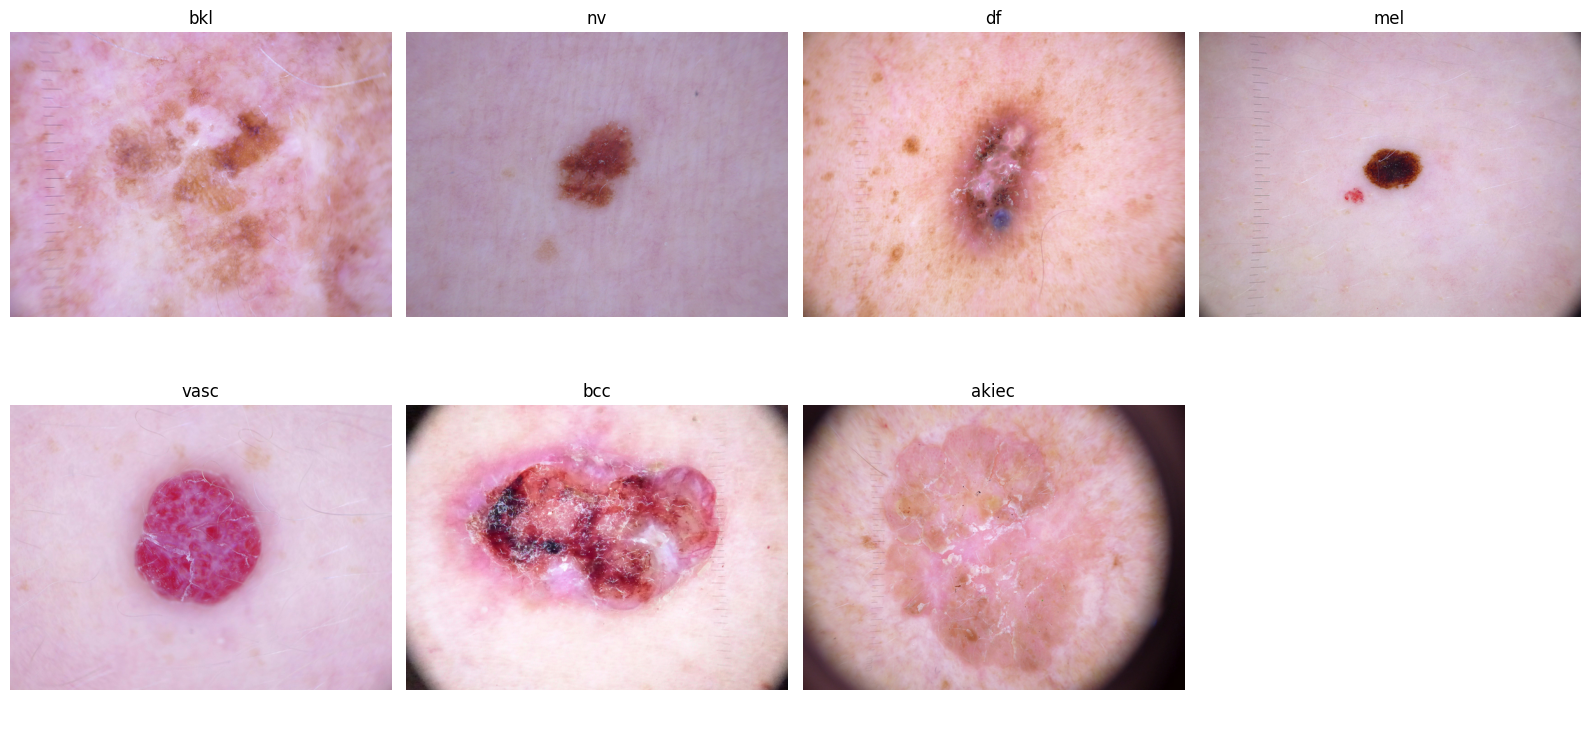

In [7]:

def showimagedata():
    data_dir = Path('data')
    img_dirs = sorted([d for d in data_dir.iterdir() if d.is_dir() and 'images' in d.name])

    classes = df['dx'].unique()
    fig, axes = plt.subplots(2, 4, figsize=(16, 8))
    axes = axes.flatten()

    for i, cls in enumerate(classes):
        sample_id = df[df['dx'] == cls]['image_id'].iloc[0]
        
        matching_files = []
        for folder in img_dirs:
            found = [f for f in folder.iterdir() if f.stem.lower() == str(sample_id).lower()]
            if found:
                matching_files.extend(found)
                break
        
        if matching_files:
            img_path = matching_files[0]
            img = Image.open(img_path)
            axes[i].imshow(img)
            axes[i].set_title(cls)
            axes[i].axis('off')
            
    for j in range(len(classes), len(axes)):
        axes[j].axis('off')
        
    plt.tight_layout()
    plt.show()
showimagedata()

Посмотрим на распределение элементов внутри каждого класса

In [11]:
class_counts = df['dx'].value_counts().sort_index()
print("Class distribution:")
for cls, count in class_counts.items():
    print(f"{cls}: {count} ({count/len(df)*100:.1f}%)")

Class distribution:
akiec: 327 (3.3%)
bcc: 514 (5.1%)
bkl: 1099 (11.0%)
df: 115 (1.1%)
mel: 1113 (11.1%)
nv: 6705 (66.9%)
vasc: 142 (1.4%)


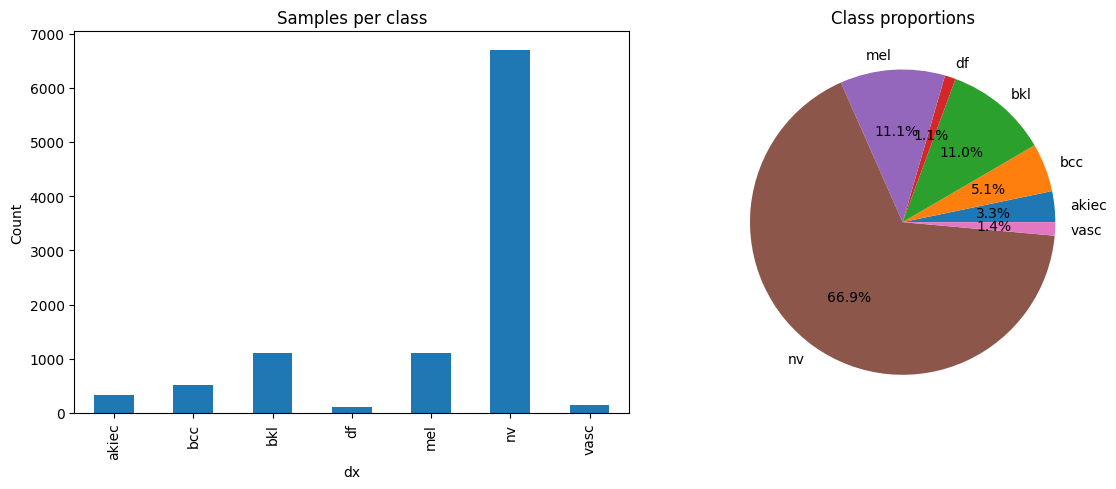

In [12]:
def showdiagramdata():
    fig, axes = plt.subplots(1, 2, figsize=(12, 5))

    class_counts.plot(kind='bar', ax=axes[0])
    axes[0].set_title('Samples per class')
    axes[0].set_ylabel('Count')

    class_counts.plot(kind='pie', ax=axes[1], autopct='%1.1f%%')
    axes[1].set_ylabel('')
    axes[1].set_title('Class proportions')

    plt.tight_layout()
    plt.show()
    
showdiagramdata()

&nbsp;&nbsp;&nbsp;&nbsp;Заметим, что данные распределены крайне неравномерно, больше элементов, который представляют собой доброкачественные
опухоли. Общее количество изображений < 10.000, поэтому необходимо расширить датасет, добавив немного изображений редких классов, чтобы модель их лучше различала. Для этого применим аугментации к некоторым изображениям (отразим, повернем, сдвинем, увеличим яркость). <br> &nbsp;&nbsp;&nbsp;&nbsp;
Таким образом мы сохраним "качественное распределение" (если в начальном датасете выполнялось, что n > m, где n - количество элементов одно гласса, m - другого, то в редактированном датасете также будет выполнятся это неравенство для любых классов), а также этим методом мы сымитируем различные условия съемки. 

### Расчёт количества аугментаций

После анализа распределения классов было выявлено существенное преобладание класса NV и недостаток изображений для классов DF, VASC, AKIEC и BCC. Такая ситуация может привести к тому, что модель будет ориентироваться преимущественно на наиболее представленные категории и хуже распознавать редкие заболевания.

Для частичной компенсации дисбаланса используется аугментация данных. В качестве целевого значения выбрано 2000 изображений на класс. Для каждого класса вычисляется количество дополнительных изображений, необходимых для достижения данного порога. Новые образцы генерируются с помощью случайных преобразований исходных изображений (повороты, отражения, изменение яркости и контрастности).

Такой подход позволяет увеличить разнообразие обучающей выборки, улучшить обобщающую способность модели и одновременно сохранить исходное соотношение между классами без чрезмерного дублирования данных.

In [13]:
target_threshold = 2000
class_counts = df['dx'].value_counts()
augment_counts = {cls: max(0, target_threshold - count) for cls, count in class_counts.items()}

### Аугментация и сохранение на диск

In [14]:
AUG_DIR = Path('data/augmented')
AUG_DIR.mkdir(exist_ok=True)

strong_tf = transforms.Compose([
    transforms.Resize((256, 256)),
    transforms.RandomCrop((224, 224)),
    transforms.RandomHorizontalFlip(),
    transforms.RandomVerticalFlip(),
    transforms.RandomRotation(30),
    transforms.ColorJitter(0.4, 0.4, 0.4, 0.1),
    transforms.ToTensor(),
])

img_dirs = [Path('data/HAM10000_images_part_1'), Path('data/HAM10000_images_part_2')]
img_map = {p.stem: p for d in img_dirs for p in d.glob('*.jpg')}

new_rows = []
for cls, count in augment_counts.items():
    if count <= 0:
        continue
    cls_mask = df['dx'] == cls
    cls_indices = df[cls_mask].index.tolist()
    
    for _ in range(count):
        src_idx = np.random.choice(cls_indices)
        row = df.iloc[src_idx]
        src_path = img_map.get(row['image_id'])
        if not src_path or not src_path.exists():
            continue
        
        img = Image.open(src_path).convert('RGB')
        aug_tensor = strong_tf(img)
        
        new_id = f"aug_{row['image_id']}_{np.random.randint(10000)}"
        transforms.ToPILImage()(aug_tensor).save(AUG_DIR / f"{new_id}.jpg")
        
        new_row = row.copy()
        new_row['image_id'] = new_id
        new_rows.append(new_row)

if new_rows:
    df = pd.concat([df, pd.DataFrame(new_rows)], ignore_index=True)
    img_map.update({p.stem: p for p in AUG_DIR.glob('*.jpg')})

class_counts = df['dx'].value_counts()

### Математика штрафования

Несмотря на применение аугментаций, распределение классов остается несбалансированным. В таких условиях стандартная функция потерь будет сильнее учитывать ошибки на многочисленных классах и практически игнорировать редкие категории.

Для решения этой проблемы каждому классу назначается индивидуальный вес, обратно пропорциональный числу его представителей в обучающей выборке:

W_k = N / (K * n_k)
где N — общее число изображений, K — количество классов, n_k — число объектов класса k.

При таком подходе ошибки на редких классах получают больший штраф, чем ошибки на распространённых. Это заставляет модель уделять больше внимания недостаточно представленным заболеваниям и способствует росту метрики Macro F1, которая является основной метрикой качества в данной задаче.

In [9]:
classes = df['dx'].unique()
class_to_idx = {cls: idx for idx, cls in enumerate(classes)}

total = len(df)
K = len(classes)
weights = {cls: total / (K * count) for cls, count in class_counts.items()}
weight_tensor = torch.tensor([weights[cls] for cls in classes])

In [10]:
lesion_info = df.groupby('lesion_id')['dx'].first().reset_index()
lesion_info = lesion_info.sample(frac=1, random_state=42).reset_index(drop=True)

split_idx = int(len(lesion_info) * 0.8)
train_lesions = lesion_info.iloc[:split_idx]['lesion_id']
val_lesions = lesion_info.iloc[split_idx:]['lesion_id']

train_df = df[df['lesion_id'].isin(train_lesions)].reset_index(drop=True)
val_df = df[df['lesion_id'].isin(val_lesions)].reset_index(drop=True)

train_df['label'] = train_df['dx'].map(class_to_idx)
val_df['label'] = val_df['dx'].map(class_to_idx)

### Dataset и DataLoader

In [11]:
train_tf = transforms.Compose([
    transforms.Resize((256, 256)),
    transforms.RandomCrop((224, 224)),
    transforms.RandomHorizontalFlip(),
    transforms.RandomRotation(15),
    transforms.ColorJitter(0.2, 0.2),
    transforms.ToTensor(),
    transforms.Normalize([0.485, 0.456, 0.406], [0.229, 0.224, 0.225])
])

val_tf = transforms.Compose([
    transforms.Resize((224, 224)),
    transforms.ToTensor(),
    transforms.Normalize([0.485, 0.456, 0.406], [0.229, 0.224, 0.225])
])


criterion = nn.CrossEntropyLoss(weight=weight_tensor)

In [12]:
class SkinDataset(Dataset):
    def __init__(self, dataframe, img_map, transform=None):
        self.df = dataframe
        self.img_map = img_map
        self.transform = transform

    def __len__(self):
        return len(self.df)

    def __getitem__(self, idx):
        row = self.df.iloc[idx]
        path = self.img_map.get(row['image_id'])
        img = Image.open(path).convert('RGB')
        if self.transform:
            img = self.transform(img)
        return img, torch.tensor(row['label'], dtype=torch.long)

train_ds = SkinDataset(train_df, img_map, transform=train_tf)
val_ds = SkinDataset(val_df, img_map, transform=val_tf)   
train_loader = DataLoader(train_ds, batch_size=32, shuffle=True, num_workers=0)
val_loader = DataLoader(val_ds, batch_size=32, shuffle=False, num_workers=0)



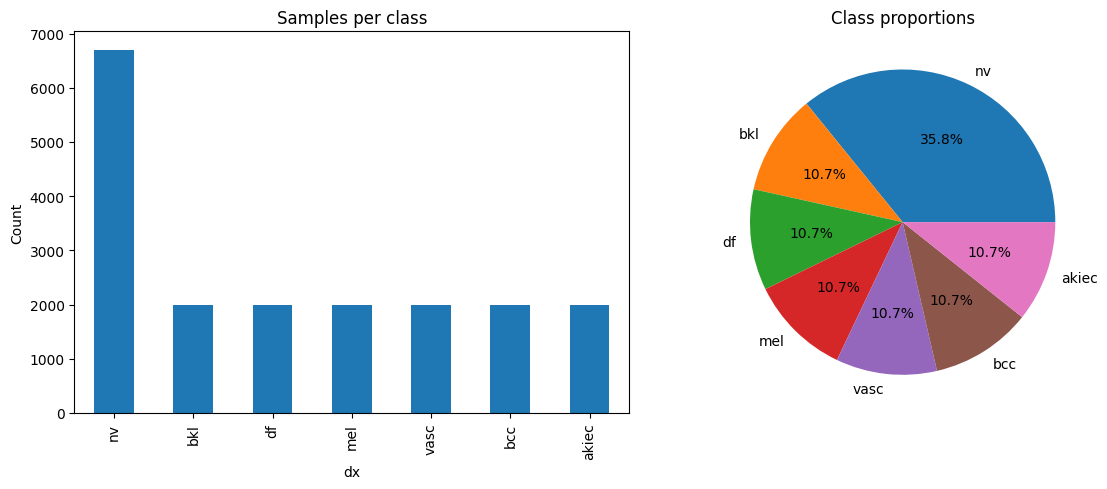

In [13]:
showdiagramdata()

## Модель и обучение


In [14]:
device = torch.device('mps' if torch.backends.mps.is_available() else 'cpu')
print(f"Using device: {device}")

Using device: mps


In [ ]:
class SkinCNN(nn.Module):
    def __init__(self, num_classes=7):
        super(SkinCNN, self).__init__()
        
        self.features = nn.Sequential(
            # Block 1
            nn.Conv2d(3, 32, kernel_size=3, padding=1),
            nn.BatchNorm2d(32),
            nn.ReLU(inplace=True),
            nn.MaxPool2d(2, 2),
            
            # Block 2
            nn.Conv2d(32, 64, kernel_size=3, padding=1),
            nn.BatchNorm2d(64),
            nn.ReLU(inplace=True),
            nn.MaxPool2d(2, 2),
            
            # Block 3
            nn.Conv2d(64, 128, kernel_size=3, padding=1),
            nn.BatchNorm2d(128),
            nn.ReLU(inplace=True),
            nn.MaxPool2d(2, 2),
            
            # Block 4
            nn.Conv2d(128, 256, kernel_size=3, padding=1),
            nn.BatchNorm2d(256),
            nn.ReLU(inplace=True),
            nn.MaxPool2d(2, 2),
        )
        
        self.classifier = nn.Sequential(
            nn.Flatten(),
            nn.Linear(256 * 14 * 14, 512), # 14x14 comes from 224 input / 16 pooling
            nn.ReLU(inplace=True),
            nn.Dropout(0.5),
            nn.Linear(512, num_classes)
        )

    def forward(self, x):
        x = self.features(x)
        x = self.classifier(x)
        return x

In [ ]:
model = SkinCNN(num_classes=7).to(device)
criterion = nn.CrossEntropyLoss(weight=weight_tensor.to(device))
optimizer = optim.Adam(model.parameters(), lr=1e-3, weight_decay=1e-4)
scheduler = optim.lr_scheduler.ReduceLROnPlateau(optimizer, mode='min', patience=3, factor=0.5)


 Сохранение весов модели

In [15]:
def save_model_weights(model, model_name):
    from datetime import datetime

    model_dir = Path('my-models')
    model_dir.mkdir(parents=True, exist_ok=True)
    timestamp = datetime.now().strftime('%Y%m%d_%H%M%S_%f')
    weights_path = model_dir / f'{model_name}_{timestamp}.pth'
    torch.save(model.state_dict(), weights_path)
    print(f'Веса модели сохранены: {weights_path.resolve()}')
    return weights_path

In [16]:
def plot_live(history):
    clear_output(wait=True)
    fig, (ax1, ax2) = plt.subplots(1, 2, figsize=(14, 5))
    
    ax1.plot(history['train_loss'], label='Train')
    ax1.plot(history['val_loss'], label='Val')
    ax1.set_title('Loss')
    ax1.set_xlabel('Epoch')
    ax1.legend()
    ax1.grid(True)
    
    ax2.plot(history['val_f1'], color='orange')
    ax2.set_title('Macro F1 Score (Val)')
    ax2.set_xlabel('Epoch')
    ax2.set_ylim([0, 1])
    ax2.grid(True)
    
    plt.tight_layout()
    plt.show()

Обучение базовой модели

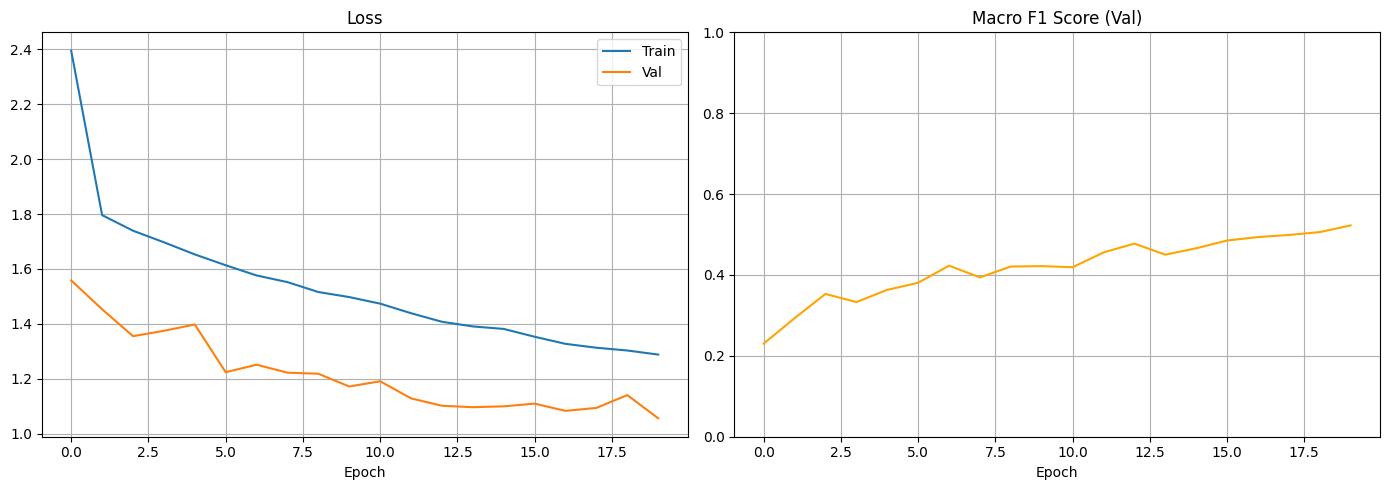

Epoch 20/20 | LR: 1.00e-03
Train Loss: 1.2879 | Val Loss: 1.0555 | Val F1: 0.5225


In [ ]:
model = SkinCNN(num_classes=7).to(device)
criterion = nn.CrossEntropyLoss(weight=weight_tensor.to(device))
optimizer = optim.Adam(model.parameters(), lr=1e-3, weight_decay=1e-4)
scheduler = optim.lr_scheduler.ReduceLROnPlateau(optimizer, mode='min', patience=3, factor=0.5)

EPOCHS = 20
history = {'train_loss': [], 'val_loss': [], 'val_f1': []}

for epoch in range(EPOCHS):  ## надо заменить на learn(), но перезапускать всю ячейку очень долго, т.к обучение длится около дву часов на m4
    # Train
    model.train()
    running_loss = 0
    for inputs, labels in train_loader:
        inputs, labels = inputs.to(device), labels.to(device)
        optimizer.zero_grad()
        outputs = model(inputs)
        loss = criterion(outputs, labels)
        loss.backward()
        optimizer.step()
        running_loss += loss.item()
    
    # Validate
    model.eval()
    val_loss = 0
    val_preds, val_labels = [], []
    with torch.no_grad():
        for inputs, labels in val_loader:
            inputs, labels = inputs.to(device), labels.to(device)
            outputs = model(inputs)
            loss = criterion(outputs, labels)
            val_loss += loss.item()
            val_preds.extend(outputs.argmax(1).cpu().numpy())
            val_labels.extend(labels.cpu().numpy())
    
    # Metrics
    train_loss = running_loss / len(train_loader)
    val_loss_avg = val_loss / len(val_loader)
    f1 = f1_score(val_labels, val_preds, average='macro')
    
    history['train_loss'].append(train_loss)
    history['val_loss'].append(val_loss_avg)
    history['val_f1'].append(f1)
    
    scheduler.step(val_loss_avg)
    
    # Live update
    plot_live(history)
    print(f"Epoch {epoch+1}/{EPOCHS} | LR: {optimizer.param_groups[0]['lr']:.2e}")
    print(f"Train Loss: {train_loss:.4f} | Val Loss: {val_loss_avg:.4f} | Val F1: {f1:.4f}")

save_model_weights(model, 'skin-cnn')


### Анализ результатов


Проблемы текущей модели: <br>
Macro F1 = 0.52 — низкое качество, модель плохо различает редкие классы <br>
36 минут на эпоху — неприемлемо медленно для экспериментов <br>
Val Loss < Train Loss — модель недообучается (underfitting), а не переобучается <br>

<br><br>

Причины:<br>
Linear(256*14*14, 512) создает 25 млн параметров — слишком много, медленно сходится <br>
Обычный Adam без затухания LR застревает в локальных минимумах<br>
num_workers=0 грузит данные последовательно<br>

In [17]:
import torch.nn.functional as F

class ResidualBlock(nn.Module):
    def __init__(self, in_channels, out_channels, stride=1):
        super().__init__()
        self.conv1 = nn.Conv2d(in_channels, out_channels, 3, stride=stride, padding=1, bias=False)
        self.bn1 = nn.BatchNorm2d(out_channels)
        self.conv2 = nn.Conv2d(out_channels, out_channels, 3, padding=1, bias=False)
        self.bn2 = nn.BatchNorm2d(out_channels)
        
        self.shortcut = nn.Sequential()
        if stride != 1 or in_channels != out_channels:
            self.shortcut = nn.Sequential(
                nn.Conv2d(in_channels, out_channels, 1, stride=stride, bias=False),
                nn.BatchNorm2d(out_channels)
            )
    
    def forward(self, x):
        out = F.relu(self.bn1(self.conv1(x)))
        out = self.bn2(self.conv2(out))
        out += self.shortcut(x)
        out = F.relu(out)
        return out
    
class ImprovedSkinCNN(nn.Module): ## другая заготовка (не успел протестировтаь)
    def __init__(self, num_classes=7):
        super().__init__()
        
        self.conv1 = nn.Conv2d(3, 32, 3, padding=1, bias=False)
        self.bn1 = nn.BatchNorm2d(32)
        
        # Residual blocks
        self.layer1 = self._make_layer(32, 64, 2)
        self.layer2 = self._make_layer(64, 128, 2)
        self.layer3 = self._make_layer(128, 256, 2)
        self.layer4 = self._make_layer(256, 512, 2)
        
        self.gap = nn.AdaptiveAvgPool2d(1)
        self.dropout = nn.Dropout(0.5)
        self.fc = nn.Linear(512, num_classes)
        
    def _make_layer(self, in_channels, out_channels, stride):
        return nn.Sequential(
            ResidualBlock(in_channels, out_channels, stride),
            ResidualBlock(out_channels, out_channels, 1)
        )
    
    def forward(self, x):
        x = F.relu(self.bn1(self.conv1(x)))
        x = self.layer1(x)
        x = self.layer2(x)
        x = self.layer3(x)
        x = self.layer4(x)
        x = self.gap(x)
        x = self.dropout(x)
        x = self.fc(x.view(x.size(0), -1))
        return x


In [ ]:
# 1. Focal Loss для несбалансированных классов
class FocalLoss(nn.Module):
    def __init__(self, alpha=1, gamma=2):
        super().__init__()
        self.alpha = alpha
        self.gamma = gamma
    
    def forward(self, inputs, targets):
        ce_loss = F.cross_entropy(inputs, targets, reduction='none')
        pt = torch.exp(-ce_loss)
        focal_loss = self.alpha * (1-pt)**self.gamma * ce_loss
        return focal_loss.mean()

# 2. Cosine Annealing с warmup
scheduler = optim.lr_scheduler.CosineAnnealingLR(optimizer, T_max=20, eta_min=1e-6)

# 3. Label smoothing
criterion = nn.CrossEntropyLoss(label_smoothing=0.1)

# 4. Gradient clipping
torch.nn.utils.clip_grad_norm_(model.parameters(), max_norm=1.0)

NameError: name 'model' is not defined

In [51]:
train_transform = transforms.Compose([
    transforms.Resize((256, 256)),
    transforms.RandomCrop(224),
    transforms.RandomHorizontalFlip(),
    transforms.RandomVerticalFlip(),
    transforms.RandomRotation(15),
    transforms.ColorJitter(brightness=0.2, contrast=0.2, saturation=0.2),
    transforms.RandomAffine(degrees=0, translate=(0.1, 0.1)),
    transforms.ToTensor(),
    transforms.Normalize([0.485, 0.456, 0.406], [0.229, 0.224, 0.225])
])

In [20]:
def learn(model, criterion, optimizer, scheduler):
    EPOCHS = 20
    history = {'train_loss': [], 'val_loss': [], 'val_f1': []}

    for epoch in range(EPOCHS):
        # Train
        model.train()
        running_loss = 0
        for inputs, labels in train_loader:
            inputs, labels = inputs.to(device), labels.to(device)
            optimizer.zero_grad()
            outputs = model(inputs)
            loss = criterion(outputs, labels)
            loss.backward()
            optimizer.step()
            running_loss += loss.item()
        
        # Validate
        model.eval()
        val_loss = 0
        val_preds, val_labels = [], []
        with torch.no_grad():
            for inputs, labels in val_loader:
                inputs, labels = inputs.to(device), labels.to(device)
                outputs = model(inputs)
                loss = criterion(outputs, labels)
                val_loss += loss.item()
                val_preds.extend(outputs.argmax(1).cpu().numpy())
                val_labels.extend(labels.cpu().numpy())
        
        # Metrics
        train_loss = running_loss / len(train_loader)
        val_loss_avg = val_loss / len(val_loader)
        f1 = f1_score(val_labels, val_preds, average='macro')
        
        history['train_loss'].append(train_loss)
        history['val_loss'].append(val_loss_avg)
        history['val_f1'].append(f1)
        
        scheduler.step(val_loss_avg)
        
        # Live update
        plot_live(history)
        print(f"Epoch {epoch+1}/{EPOCHS} | LR: {optimizer.param_groups[0]['lr']:.2e}")
        print(f"Train Loss: {train_loss:.4f} | Val Loss: {val_loss_avg:.4f} | Val F1: {f1:.4f}")

    save_model_weights(model, type(model).__name__)



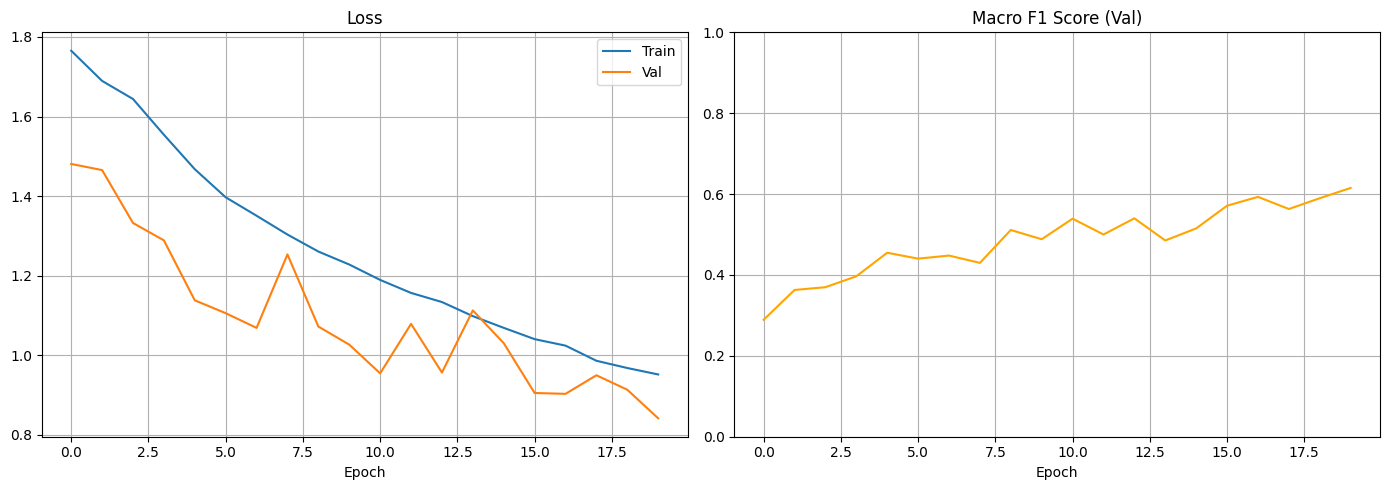

Epoch 20/20 | LR: 9.96e-04
Train Loss: 0.9519 | Val Loss: 0.8417 | Val F1: 0.6152
Веса модели сохранены: /Users/dmitrij/VsProjects/curswork/my-models/ProSkinCNN_20261022_231200_476285.pth


: 

In [ ]:
class ResBlock(nn.Module):
    def __init__(self, in_c, out_c, stride=1):
        super().__init__()
        self.conv1 = nn.Conv2d(in_c, out_c, 3, stride, 1, bias=False)
        self.bn1 = nn.BatchNorm2d(out_c)
        self.conv2 = nn.Conv2d(out_c, out_c, 3, 1, 1, bias=False)
        self.bn2 = nn.BatchNorm2d(out_c)
        
        self.skip = nn.Sequential()
        if stride != 1 or in_c != out_c:
            self.skip = nn.Sequential(
                nn.Conv2d(in_c, out_c, 1, stride, bias=False),
                nn.BatchNorm2d(out_c)
            )

    def forward(self, x):
        out = torch.relu(self.bn1(self.conv1(x)))
        out = self.bn2(self.conv2(out))
        return torch.relu(out + self.skip(x))

class ProSkinCNN(nn.Module):
    def __init__(self, num_classes=7):
        super().__init__()
        self.net = nn.Sequential(
            nn.Conv2d(3, 32, 3, 1, 1, bias=False),
            nn.BatchNorm2d(32),
            nn.ReLU(inplace=True),
            
            ResBlock(32, 64, 2),
            ResBlock(64, 128, 2),
            ResBlock(128, 256, 2),
            ResBlock(256, 512, 2),
            
            nn.AdaptiveAvgPool2d(1),
            nn.Flatten(),
            nn.Dropout(0.2),
            nn.Linear(512, num_classes)
        )

    def forward(self, x):
        return self.net(x)

model = ProSkinCNN(num_classes=7).to('mps')
criterion = nn.CrossEntropyLoss(weight=weight_tensor.to(device))
optimizer = torch.optim.AdamW(model.parameters(), lr=1e-3, weight_decay=1e-4)
scheduler = torch.optim.lr_scheduler.CosineAnnealingLR(optimizer, T_max=20)
learn(model, criterion, optimizer, scheduler)

# Сравнение и анализ результатов

После 20 эпох обучения модель ProSkinCNN достигла значения Macro F1 = 0.5948 при значениях Train Loss = 0.9442 и Val Loss = 0.8863.

Графики обучения демонстрируют устойчивое снижение функции потерь как на обучающей, так и на валидационной выборке. Отсутствие расхождения между кривыми позволяет сделать вывод об отсутствии выраженного переобучения. Более низкое значение Val Loss по сравнению с Train Loss может объясняться использованием аугментаций и взвешенной функции потерь на этапе обучения, что делает обучающую задачу более сложной.

По сравнению с базовой архитектурой SkinCNN качество классификации увеличилось с Macro F1 = 0.5225 до Macro F1 = 0.5948, что соответствует приросту примерно на 14 %. Улучшение связано с использованием остаточных соединений (Residual Connections), которые облегчают распространение градиента в глубоких сетях, а также с заменой крупного полносвязного слоя на Global Average Pooling, что позволило существенно сократить число параметров модели.

Несмотря на достигнутый результат, качество классификации остаётся ограниченным из-за небольшого объёма датасета и сильного дисбаланса классов. Дальнейшее повышение точности может быть достигнуто за счёт использования предобученных архитектур (ResNet, EfficientNet), более сложных методов аугментации данных и увеличения объёма обучающей выборки.

## Энтропия изображения

Для каждого RGB-пикселя выбираем ближайший по евклидову расстоянию цвет: чёрный `(0, 0, 0)` или белый `(255, 255, 255)`. Затем считаем частоты соседних пар отдельно вправо и вниз. По каждой таблице переходов вычисляем условную энтропию цвета соседнего пикселя при известном цвете текущего. Результат — среднее двух направлений в битах (от 0 до 1).


In [16]:
def image_transition_entropy(image):
    """Условная энтропия переходов вправо и вниз для PIL RGB-изображения.

    Возвращает энтропии направлений, их среднее и таблицы переходов.
    Строка таблицы — цвет текущего пикселя, столбец — цвет соседа:
    0 = чёрный, 1 = белый.
    """
    pixels = np.asarray(image.convert('RGB'), dtype=np.int32)
    if pixels.shape[0] < 2 or pixels.shape[1] < 2:
        raise ValueError('Изображение должно иметь ширину и высоту не меньше 2 пикселей')

    distance_to_black = np.sum(pixels ** 2, axis=2)
    distance_to_white = np.sum((pixels - 255) ** 2, axis=2)
    binary = (distance_to_white < distance_to_black).astype(np.uint8)

    def pair_counts(current, neighbor):
        pairs = 2 * current.ravel().astype(np.int32) + neighbor.ravel()
        return np.bincount(pairs, minlength=4).reshape(2, 2)

    def conditional_entropy(counts):
        row_totals = counts.sum(axis=1, keepdims=True)
        probabilities = np.divide(
            counts, row_totals, out=np.zeros((2, 2), dtype=float), where=row_totals != 0
        )
        nonzero = probabilities > 0
        return float(-np.sum(
            (counts[nonzero] / counts.sum()) * np.log2(probabilities[nonzero])
        ))

    horizontal_pairs = pair_counts(binary[:, :-1], binary[:, 1:])
    vertical_pairs = pair_counts(binary[:-1, :], binary[1:, :])
    horizontal = conditional_entropy(horizontal_pairs)
    vertical = conditional_entropy(vertical_pairs)

    return {
        'horizontal': horizontal,
        'vertical': vertical,
        'mean': (horizontal + vertical) / 2,
        'horizontal_pairs': horizontal_pairs,
        'vertical_pairs': vertical_pairs,
    }


### Примеры на изображениях из HAM10000

Сверху показаны исходные изображения, снизу — их перевод в два цвета. Между рядами для каждого изображения указаны условные энтропии переходов вправо и вниз и их среднее. Светлый фон почти полностью становится белым, поэтому значения небольшие: соседний цвет обычно предсказуем по текущему пикселю.


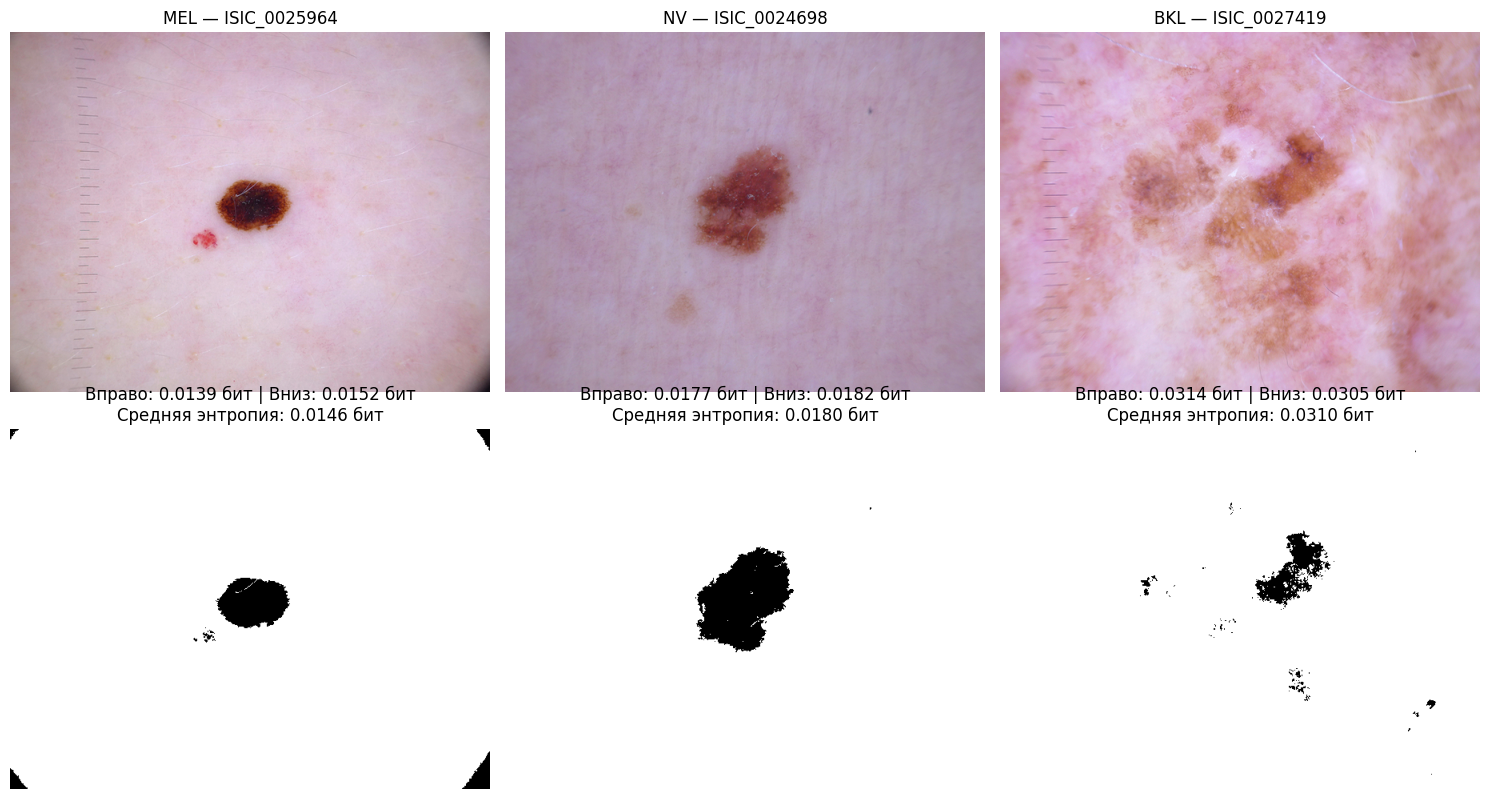

In [17]:
example_images = [
    ('MEL', Path('data/HAM10000_images_part_1/ISIC_0025964.jpg')),
    ('NV', Path('data/HAM10000_images_part_1/ISIC_0024698.jpg')),
    ('BKL', Path('data/HAM10000_images_part_1/ISIC_0027419.jpg')),
]

fig, axes = plt.subplots(2, len(example_images), figsize=(15, 8))
for column, (diagnosis, path) in enumerate(example_images):
    with Image.open(path) as source:
        image = source.convert('RGB')
    entropy = image_transition_entropy(image)

    pixels = np.asarray(image, dtype=np.int32)
    distance_to_black = np.sum(pixels ** 2, axis=2)
    distance_to_white = np.sum((pixels - 255) ** 2, axis=2)
    binary = distance_to_white < distance_to_black

    axes[0, column].imshow(image)
    axes[0, column].set_title(f'{diagnosis} — {path.stem}')
    axes[0, column].axis('off')

    axes[1, column].imshow(binary, cmap='gray', vmin=0, vmax=1)
    axes[1, column].set_title(
        f'Вправо: {entropy["horizontal"]:.4f} бит | '
        f'Вниз: {entropy["vertical"]:.4f} бит\n'
        f'Средняя энтропия: {entropy["mean"]:.4f} бит'
    )
    axes[1, column].axis('off')

plt.tight_layout()
plt.show()


### Энтропия переходов для 64 цветов

Каждый канал RGB делится на четыре фиксированных интервала: `0–63`, `64–127`, `128–191`, `192–255`. Комбинация трёх каналов даёт 64 категории. Для соседних пикселей вправо и вниз строятся отдельные таблицы переходов `64 × 64`; из них вычисляется условная энтропия. Функция возвращает значения в битах и среднее, нормированное делением на `log₂(64) = 6`. Размер изображения не меняется; центральную область при необходимости можно передать отдельно.


In [18]:
def color_transition_entropy(rgb):
    """Условная энтропия соседних 64 цветовых категорий в RGB-массиве uint8.

    Возвращает right_bits, down_bits, mean_bits и mean_normalized.
    """
    rgb = np.asarray(rgb)
    if rgb.dtype != np.uint8 or rgb.ndim != 3 or rgb.shape[2] != 3:
        raise ValueError('Ожидается RGB-массив формы (height, width, 3) с dtype uint8')
    if rgb.shape[0] < 2 or rgb.shape[1] < 2:
        raise ValueError('Высота и ширина должны быть не меньше 2 пикселей')

    levels = rgb.astype(np.int32) // 64
    categories = 16 * levels[:, :, 0] + 4 * levels[:, :, 1] + levels[:, :, 2]

    def transition_counts(current, neighbor):
        pair_ids = 64 * current.ravel() + neighbor.ravel()
        return np.bincount(pair_ids, minlength=64 * 64).reshape(64, 64)

    def conditional_entropy(counts):
        rows, columns = np.nonzero(counts)
        frequencies = counts[rows, columns].astype(np.float64)
        row_totals = counts.sum(axis=1)
        total = counts.sum()
        return float(-np.sum(
            (frequencies / total) * np.log2(frequencies / row_totals[rows])
        ))

    right_counts = transition_counts(categories[:, :-1], categories[:, 1:])
    down_counts = transition_counts(categories[:-1, :], categories[1:, :])
    right_bits = conditional_entropy(right_counts)
    down_bits = conditional_entropy(down_counts)
    mean_bits = (right_bits + down_bits) / 2
    return {
        'right_bits': right_bits,
        'down_bits': down_bits,
        'mean_bits': mean_bits,
        'mean_normalized': mean_bits / 6,
    }


#### Примеры для тех же трёх изображений

Сверху — исходные снимки, снизу — результат разбиения RGB на 64 категории (для отображения каждой категории взята середина её интервала). Значения в битах показывают предсказуемость соседнего цвета; `mean_normalized` позволяет сравнивать результат в диапазоне от 0 до 1.


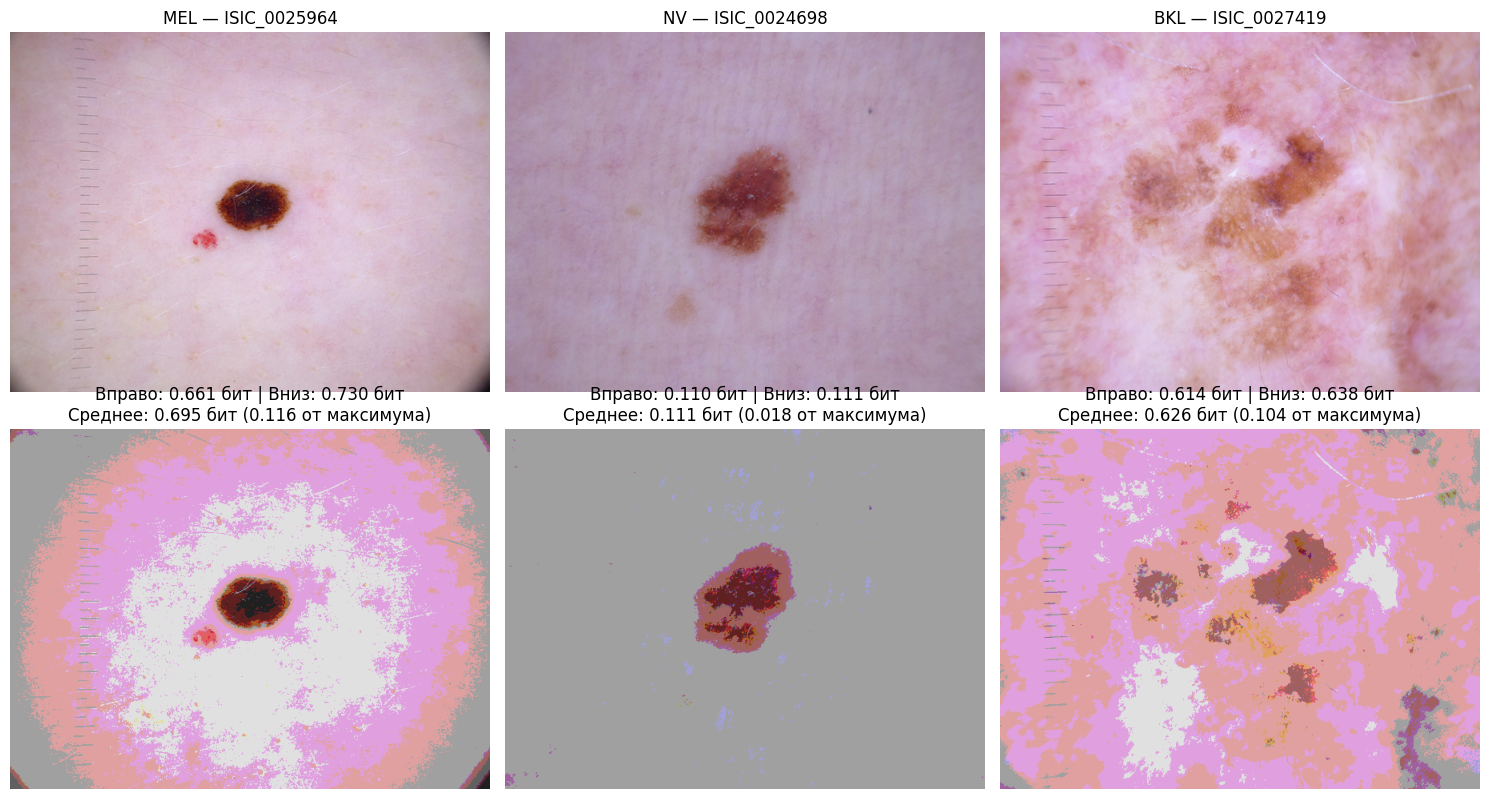

In [19]:
example_images_64 = [
    ('MEL', Path('data/HAM10000_images_part_1/ISIC_0025964.jpg')),
    ('NV', Path('data/HAM10000_images_part_1/ISIC_0024698.jpg')),
    ('BKL', Path('data/HAM10000_images_part_1/ISIC_0027419.jpg')),
]

fig, axes = plt.subplots(2, len(example_images_64), figsize=(15, 8))
for column, (diagnosis, path) in enumerate(example_images_64):
    with Image.open(path) as source:
        rgb = np.asarray(source.convert('RGB'), dtype=np.uint8)
    entropy_64 = color_transition_entropy(rgb)
    quantized = (rgb // 64) * 64 + 32

    axes[0, column].imshow(rgb)
    axes[0, column].set_title(f'{diagnosis} — {path.stem}')
    axes[0, column].axis('off')

    axes[1, column].imshow(quantized)
    axes[1, column].set_title(
        f'Вправо: {entropy_64["right_bits"]:.3f} бит | '
        f'Вниз: {entropy_64["down_bits"]:.3f} бит\n'
        f'Среднее: {entropy_64["mean_bits"]:.3f} бит '
        f'({entropy_64["mean_normalized"]:.3f} от максимума)'
    )
    axes[1, column].axis('off')

plt.tight_layout()
plt.show()


## Продолжение работы с цветной энтропией

Дальше исследуем цветную энтропию при разном числе цветовых интервалов. Пусть `n` — число интервалов на каждый канал RGB; всего получается `n³` категорий. Для каждого `n` от 2 до 255 вычислим энтропию трёх исходных изображений. Затем перемешаем **уже квантованные пиксели**: частоты категорий останутся точно такими же, но пространственное соседство изменится. Сравним энтропию исходного изображения, энтропию перемешанного и разность `H_перемешанное − H_исходное`. Чем больше разность, тем сильнее эта мера улавливает структуру расположения цветов. При большом `n` число наблюдений на отдельный переход уменьшается, поэтому оценка может стать менее устойчивой.


In [20]:
def color_transition_entropy_n(n, image, *, shuffle=False, rng=None):
    """Условная энтропия RGB-изображения с n интервалами на каждый канал.

    image: PIL.Image или RGB-массив uint8 размера H×W×3.
    shuffle=True перемешивает квантованные пиксели, сохраняя частоты n³ категорий.
    """
    if isinstance(n, bool) or not isinstance(n, (int, np.integer)) or not 2 <= n <= 256:
        raise ValueError('n должно быть целым числом от 2 до 256')
    if isinstance(image, Image.Image):
        rgb = np.asarray(image.convert('RGB'), dtype=np.uint8)
    else:
        rgb = np.asarray(image)
    if rgb.dtype != np.uint8 or rgb.ndim != 3 or rgb.shape[2] != 3:
        raise ValueError('Ожидается RGB-изображение с dtype uint8 и формой H×W×3')
    if rgb.shape[0] < 2 or rgb.shape[1] < 2:
        raise ValueError('Высота и ширина должны быть не меньше 2 пикселей')

    levels = rgb.astype(np.int32) * n // 256
    categories = (levels[:, :, 0] * n + levels[:, :, 1]) * n + levels[:, :, 2]
    if shuffle:
        categories = categories.ravel().copy()
        (np.random.default_rng() if rng is None else rng).shuffle(categories)
        categories = categories.reshape(rgb.shape[:2])

    number_of_colors = n ** 3

    def direction_entropy(current, neighbor):
        # Учитываем только встреченные пары: матрица n³ × n³ при n=20 уже велика.
        pair_ids = current.ravel().astype(np.int64) * number_of_colors + neighbor.ravel()
        unique_pairs, counts = np.unique(pair_ids, return_counts=True)
        current_colors = unique_pairs // number_of_colors
        row_colors, row_starts = np.unique(current_colors, return_index=True)
        row_totals = np.add.reduceat(counts, row_starts)
        source_totals = row_totals[np.searchsorted(row_colors, current_colors)]
        probabilities = counts / source_totals
        return float(-np.sum((counts / counts.sum()) * np.log2(probabilities)))

    right_bits = direction_entropy(categories[:, :-1], categories[:, 1:])
    down_bits = direction_entropy(categories[:-1, :], categories[1:, :])
    mean_bits = (right_bits + down_bits) / 2
    return {
        'right_bits': right_bits,
        'down_bits': down_bits,
        'mean_bits': mean_bits,
        'mean_normalized': mean_bits / (3 * np.log2(n)),
    }


### Энтропия в зависимости от числа цветов

Три графика ниже построены на тех же снимках MEL, NV и BKL. Для воспроизводимости перемешивание использует фиксированный генератор случайных чисел. На третьем графике положительная разность означает, что исходное расположение пикселей предсказуемее случайного при том же распределении цветов. Графики сохраняются в `graphics/entropy/`.


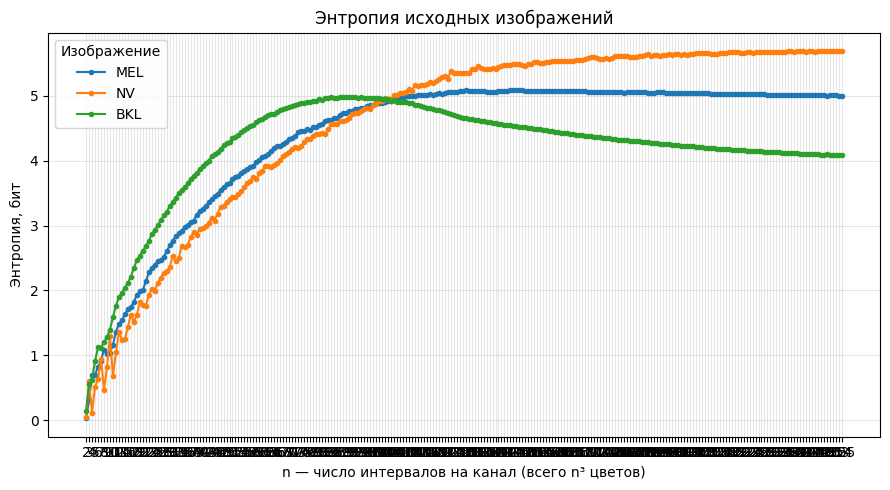

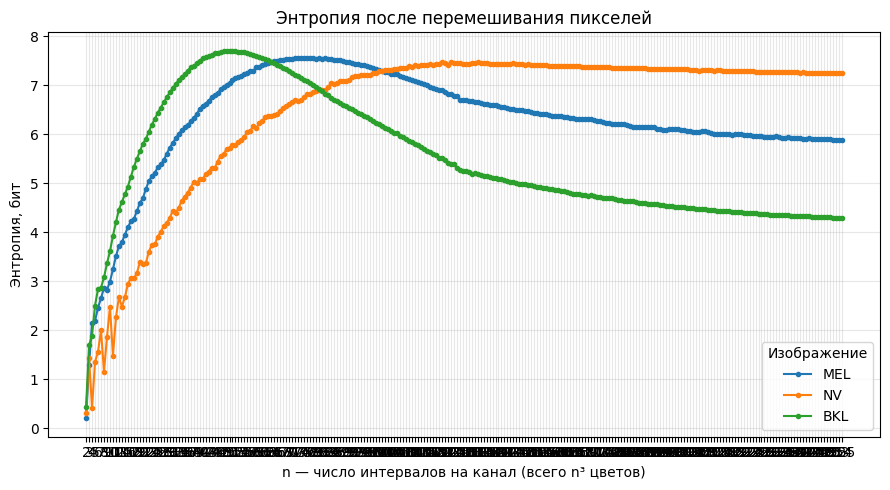

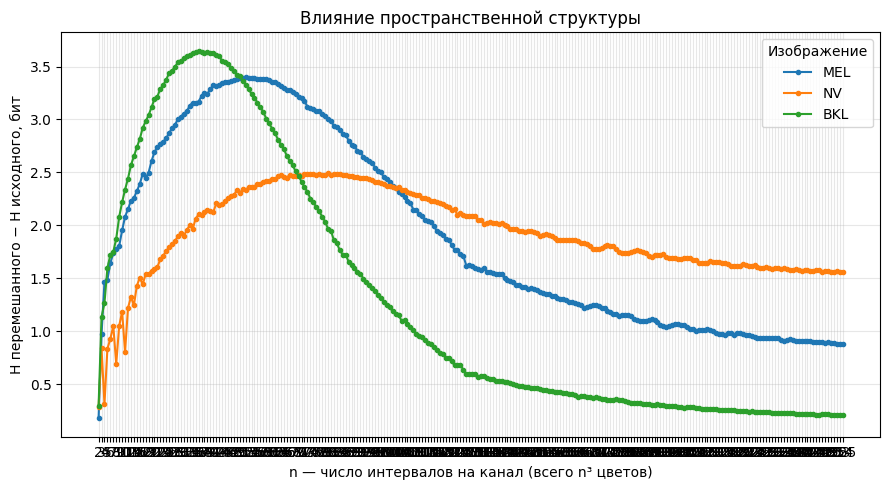

In [21]:
example_images_n = [
    ('MEL', Path('data/HAM10000_images_part_1/ISIC_0025964.jpg')),
    ('NV', Path('data/HAM10000_images_part_1/ISIC_0024698.jpg')),
    ('BKL', Path('data/HAM10000_images_part_1/ISIC_0027419.jpg')),
]
images_n = {}
for label, path in example_images_n:
    with Image.open(path) as source:
        images_n[label] = np.asarray(source.convert('RGB'), dtype=np.uint8)

n_values = np.arange(2, 256)
rng = np.random.default_rng(2026)
entropy_results = {
    label: {'original': [], 'shuffled': [], 'difference': []}
    for label in images_n
}
for n in n_values:
    for label, rgb in images_n.items():
        original_bits = color_transition_entropy_n(n, rgb)['mean_bits']
        shuffled_bits = color_transition_entropy_n(n, rgb, shuffle=True, rng=rng)['mean_bits']
        entropy_results[label]['original'].append(original_bits)
        entropy_results[label]['shuffled'].append(shuffled_bits)
        entropy_results[label]['difference'].append(shuffled_bits - original_bits)

output_dir = Path('graphics/entropy')
output_dir.mkdir(parents=True, exist_ok=True)
plots = [
    ('original', 'Энтропия исходных изображений', 'Энтропия, бит', 'entropy_original_vs_n.png'),
    ('shuffled', 'Энтропия после перемешивания пикселей', 'Энтропия, бит', 'entropy_shuffled_vs_n.png'),
    ('difference', 'Влияние пространственной структуры', 'H перемешанного − H исходного, бит', 'entropy_difference_vs_n.png'),
]
for metric, title, ylabel, filename in plots:
    fig, ax = plt.subplots(figsize=(9, 5))
    for label, values in entropy_results.items():
        ax.plot(n_values, values[metric], marker='o', markersize=3, label=label)
    ax.set_title(title)
    ax.set_xlabel('n — число интервалов на канал (всего n³ цветов)')
    ax.set_ylabel(ylabel)
    ax.set_xticks(n_values)
    ax.grid(alpha=0.3)
    ax.legend(title='Изображение')
    fig.tight_layout()
    fig.savefig(output_dir / filename, dpi=160)
    plt.show()


### Наблюдения по трём снимкам

При переборе от 2 до 255 разность энтропий достигает максимума при разных значениях n для разных снимков. В следующем эксперименте используем n = 48 как рабочее значение.


## Связь энтропии изображения и ответа ProSkinCNN

Ниже один раз проверяем сохранённую модель на **1998 исходных валидационных снимках**: разбиение по `lesion_id` и порядок семи классов восстановлены из `HAM10000_metadata.csv` тем же способом, что в ячейках обучения. Аугментированные копии в проверку не входят. По X отложена средняя условная энтропия соседних цветов при `n=48`, делённая на `3 log₂ 48`; по Y — энтропия вероятностей `softmax`, делённая на `log₂ 7`. На всех трёх панелях одинаковые пределы осей.

Ячейка ниже **не обучает модель**. Для повторного запуска в чистом ядре достаточно выполнить ячейку импортов и ячейку `color_transition_entropy_n` выше, затем эту ячейку. Она загружает веса из `my-models` и сохраняет таблицу и график в `graphics/entropy/`. Чекпойнт содержит только веса; соответствие индексов названиям классов восстановлено из текущего ноутбука, а не проверено по метаданным чекпойнта.


Всего: 1998; ошибок: 519; правильных: 1479
Чекпойнт: my-models/ProSkinCNN_20261022_231200_476285.pth


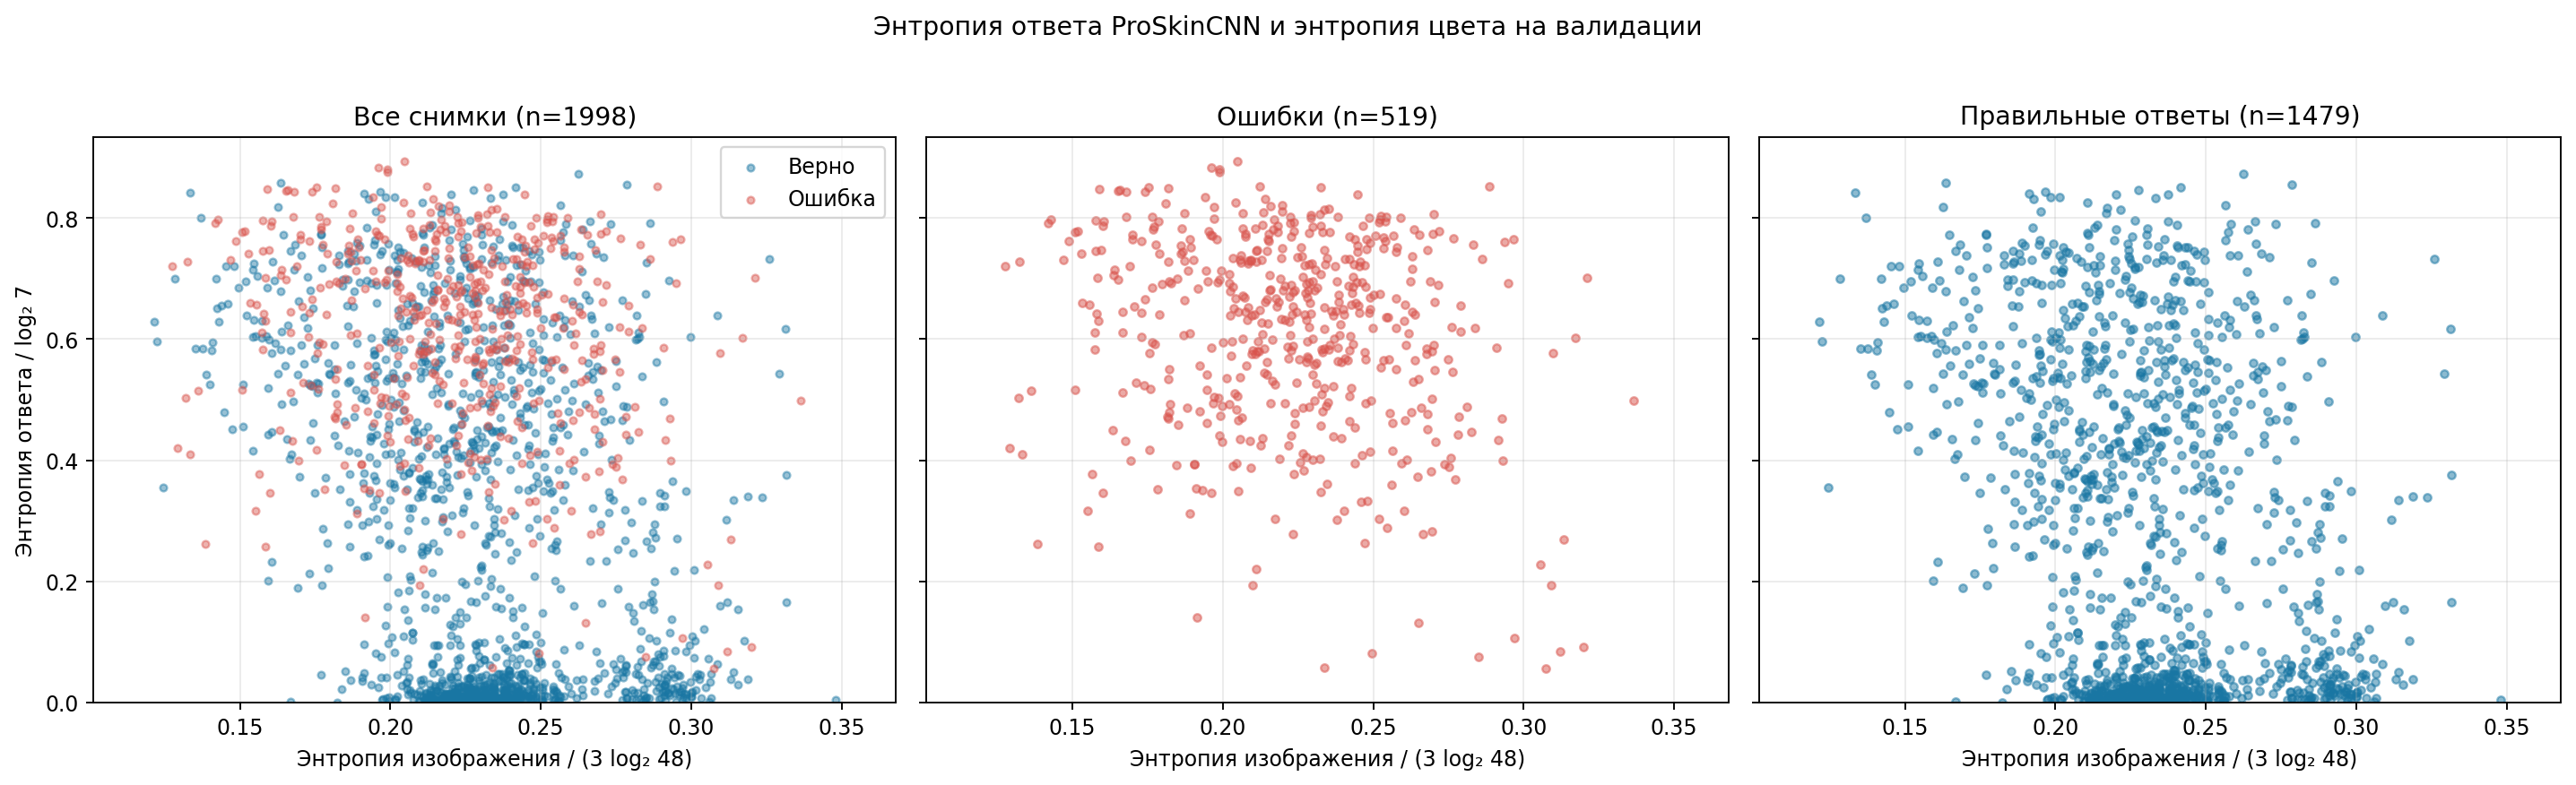

In [ ]:
# Для чистого ядра сначала выполните ячейку color_transition_entropy_n выше.
import os
from pathlib import Path

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
from PIL import Image
import torch
import torch.nn as nn
from torch.utils.data import Dataset, DataLoader
from torchvision import transforms

N_COLORS_PER_CHANNEL = 48
CHECKPOINT = Path('my-models/ProSkinCNN_20261022_231200_476285.pth')

# Только определения слоёв: ячейку обучения выше запускать не нужно.
class ValidationResBlock(nn.Module):
    def __init__(self, in_c, out_c, stride=1):
        super().__init__()
        self.conv1 = nn.Conv2d(in_c, out_c, 3, stride, 1, bias=False)
        self.bn1 = nn.BatchNorm2d(out_c)
        self.conv2 = nn.Conv2d(out_c, out_c, 3, 1, 1, bias=False)
        self.bn2 = nn.BatchNorm2d(out_c)
        self.skip = nn.Sequential()
        if stride != 1 or in_c != out_c:
            self.skip = nn.Sequential(
                nn.Conv2d(in_c, out_c, 1, stride, bias=False),
                nn.BatchNorm2d(out_c),
            )

    def forward(self, x):
        out = torch.relu(self.bn1(self.conv1(x)))
        out = self.bn2(self.conv2(out))
        return torch.relu(out + self.skip(x))


class ValidationProSkinCNN(nn.Module):
    def __init__(self, num_classes=7):
        super().__init__()
        self.net = nn.Sequential(
            nn.Conv2d(3, 32, 3, 1, 1, bias=False),
            nn.BatchNorm2d(32),
            nn.ReLU(inplace=True),
            ValidationResBlock(32, 64, 2),
            ValidationResBlock(64, 128, 2),
            ValidationResBlock(128, 256, 2),
            ValidationResBlock(256, 512, 2),
            nn.AdaptiveAvgPool2d(1),
            nn.Flatten(),
            nn.Dropout(0.2),
            nn.Linear(512, num_classes),
        )

    def forward(self, x):
        return self.net(x)


metadata = pd.read_csv('data/HAM10000_metadata.csv')
class_names = metadata['dx'].unique().tolist()
class_to_idx = {name: i for i, name in enumerate(class_names)}
lesions = metadata.groupby('lesion_id')['dx'].first().reset_index()
lesions = lesions.sample(frac=1, random_state=42).reset_index(drop=True)
validation_lesions = set(lesions.iloc[int(len(lesions) * 0.8):]['lesion_id'])
validation_rows = metadata[metadata['lesion_id'].isin(validation_lesions)].reset_index(drop=True)
image_paths = {
    path.stem: path
    for folder in ('HAM10000_images_part_1', 'HAM10000_images_part_2')
    for path in Path('data', folder).glob('*.jpg')
}
missing_ids = sorted(set(validation_rows['image_id']) - image_paths.keys())
if missing_ids:
    raise FileNotFoundError(f'Нет {len(missing_ids)} исходных изображений; пример: {missing_ids[:3]}')

validation_transform = transforms.Compose([
    transforms.Resize((224, 224)),
    transforms.ToTensor(),
    transforms.Normalize([0.485, 0.456, 0.406], [0.229, 0.224, 0.225]),
])


class ValidationEntropyDataset(Dataset):
    def __len__(self):
        return len(validation_rows)

    def __getitem__(self, index):
        row = validation_rows.iloc[index]
        with Image.open(image_paths[row['image_id']]) as source:
            image = source.convert('RGB')
        image_entropy = color_transition_entropy_n(N_COLORS_PER_CHANNEL, image)
        return (
            validation_transform(image),
            image_entropy['mean_bits'],
            image_entropy['mean_normalized'],
            class_to_idx[row['dx']],
            row['image_id'],
            row['lesion_id'],
        )


device = torch.device('mps' if torch.backends.mps.is_available() else 'cpu')
model_for_entropy = ValidationProSkinCNN(num_classes=len(class_names)).to(device)
model_for_entropy.load_state_dict(
    torch.load(CHECKPOINT, map_location=device, weights_only=True), strict=True
)
model_for_entropy.eval()
validation_loader = DataLoader(ValidationEntropyDataset(), batch_size=16, shuffle=False, num_workers=0)

records = []
with torch.inference_mode():
    for batch_index, (images, input_bits, input_normalized, labels, image_ids, lesion_ids) in enumerate(validation_loader, start=1):
        logits = model_for_entropy(images.to(device))
        probabilities = torch.softmax(logits, dim=1)
        output_bits = -(probabilities * torch.log2(probabilities.clamp_min(1e-12))).sum(dim=1).cpu().numpy()
        predicted = probabilities.argmax(dim=1).cpu().numpy()
        for i in range(len(image_ids)):
            true_index = int(labels[i])
            predicted_index = int(predicted[i])
            records.append({
                'image_id': image_ids[i],
                'lesion_id': lesion_ids[i],
                'true_class': class_names[true_index],
                'predicted_class': class_names[predicted_index],
                'correct': predicted_index == true_index,
                'input_bits': float(input_bits[i]),
                'input_normalized': float(input_normalized[i]),
                'output_bits': float(output_bits[i]),
                'output_normalized': float(output_bits[i] / np.log2(len(class_names))),
            })
        if batch_index % 25 == 0 or batch_index == len(validation_loader):
            print(f'Обработано {len(records)} из {len(validation_rows)} снимков', flush=True)

results_df = pd.DataFrame.from_records(records)
assert len(results_df) == len(validation_rows)
assert results_df['image_id'].is_unique
output_dir = Path(os.environ.get('ENTROPY_OUTPUT_DIR', 'graphics/entropy'))
output_dir.mkdir(parents=True, exist_ok=True)
results_df.to_csv(output_dir / 'validation_entropy_n48.csv', index=False)

correct = results_df['correct']
shared_xlim = (max(0.0, results_df['input_normalized'].min() - 0.02), min(1.0, results_df['input_normalized'].max() + 0.02))
shared_ylim = (max(0.0, results_df['output_normalized'].min() - 0.04), min(1.0, results_df['output_normalized'].max() + 0.04))
fig, axes = plt.subplots(1, 3, figsize=(17, 5), sharex=True, sharey=True)
groups = [
    ('Все снимки', results_df),
    ('Ошибки', results_df[~correct]),
    ('Правильные ответы', results_df[correct]),
]
for ax, (title, group) in zip(axes, groups):
    if title == 'Все снимки':
        for subset, color, label in [(group[group['correct']], '#1976a3', 'Верно'), (group[~group['correct']], '#d9544d', 'Ошибка')]:
            ax.scatter(subset['input_normalized'], subset['output_normalized'], s=11, alpha=0.45, c=color, label=label, rasterized=True)
        ax.legend(loc='upper right')
    else:
        ax.scatter(group['input_normalized'], group['output_normalized'], s=13, alpha=0.5, c='#d9544d' if title == 'Ошибки' else '#1976a3', rasterized=True)
    ax.set_title(f'{title} (n={len(group)})')
    ax.set_xlim(shared_xlim)
    ax.set_ylim(shared_ylim)
    ax.set_xlabel('Энтропия изображения / (3 log₂ 48)')
    ax.grid(alpha=0.25)
axes[0].set_ylabel('Энтропия ответа / log₂ 7')
fig.suptitle('Энтропия ответа ProSkinCNN и энтропия цвета на валидации', y=1.02)
fig.tight_layout()
fig.savefig(output_dir / 'validation_entropy_scatter_n48.png', dpi=170, bbox_inches='tight')
plt.show()
print(f'Всего: {len(results_df)}; ошибок: {(~correct).sum()}; правильных: {correct.sum()}')
print(f'Чекпойнт: {CHECKPOINT}')


## Ошибки по классам при высокой энтропии ответа

Проверим исследовательский порог `output_normalized > 0.4` на той же исходной валидационной выборке. Для каждого **истинного класса** считаем и долю ошибок среди снимков этого класса, и абсолютное число ошибок: при дисбалансе классов эти показатели отвечают на разные вопросы. Для будущего правила передачи снимка другой модели отдельно считаем ошибки по **предсказанному классу**, который доступен во время использования модели. Ниже приведены все пары истинных и ошибочно предсказанных классов.


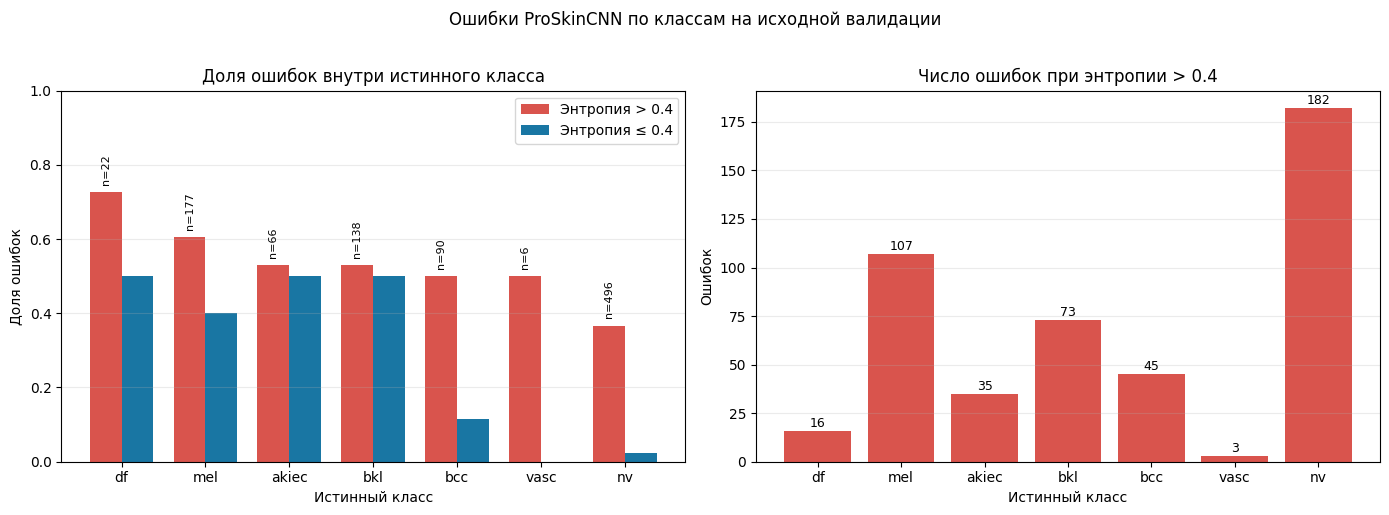

Энтропия > 0.4: 995 снимков, 461 ошибок
Доли и числа ошибок по классам:
       n_high  errors_high  error_rate_high  n_low  errors_low  error_rate_low  share_of_high_errors
df         22           16            0.727      6           3           0.500                 0.035
mel       177          107            0.605     40          16           0.400                 0.232
akiec      66           35            0.530      2           1           0.500                 0.076
bkl       138           73            0.529     28          14           0.500                 0.158
bcc        90           45            0.500     26           3           0.115                 0.098
vasc        6            3            0.500     27           0           0.000                 0.007
nv        496          182            0.367    874          21           0.024                 0.395

Куда модель относила ошибочные снимки с энтропией > 0.4:
Предсказанный класс  akiec  bcc  bkl  df  mel  nv  vasc
Истинн

In [1]:
import os
from pathlib import Path

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd

THRESHOLD = 0.4  # Нормированная энтропия ответа, от 0 до 1.
results = pd.read_csv('graphics/entropy/validation_entropy_n48.csv')
results['correct'] = results['correct'].astype(bool)
high = results[results['output_normalized'] > THRESHOLD].copy()
low = results[results['output_normalized'] <= THRESHOLD].copy()


def class_error_counts(frame):
    grouped = frame.groupby('true_class')['correct'].agg(['size', 'sum'])
    return pd.DataFrame({'n': grouped['size'], 'errors': grouped['size'] - grouped['sum']})


high_counts = class_error_counts(high)
low_counts = class_error_counts(low)
class_summary = pd.DataFrame(index=sorted(results['true_class'].unique()))
for prefix, counts in [('high', high_counts), ('low', low_counts)]:
    class_summary[f'n_{prefix}'] = counts['n']
    class_summary[f'errors_{prefix}'] = counts['errors']
    class_summary[f'error_rate_{prefix}'] = counts['errors'] / counts['n']
class_summary = class_summary.fillna(0)
class_summary['share_of_high_errors'] = class_summary['errors_high'] / class_summary['errors_high'].sum()
class_summary = class_summary.sort_values('error_rate_high', ascending=False)

output_dir = Path(os.environ.get('ENTROPY_OUTPUT_DIR', 'graphics/entropy'))
output_dir.mkdir(parents=True, exist_ok=True)
class_summary.to_csv(output_dir / 'high_entropy_class_errors.csv', index_label='true_class')

wrong_high = high[~high['correct']]
confusion = pd.crosstab(
    wrong_high['true_class'], wrong_high['predicted_class'],
    rownames=['Истинный класс'], colnames=['Предсказанный класс'],
)
predicted_counts = high.groupby('predicted_class')['correct'].agg(['size', 'sum'])
predicted_summary = pd.DataFrame({
    'n': predicted_counts['size'],
    'errors': predicted_counts['size'] - predicted_counts['sum'],
})
predicted_summary['error_rate'] = predicted_summary['errors'] / predicted_summary['n']
predicted_summary = predicted_summary.sort_values('error_rate', ascending=False)
predicted_summary.to_csv(output_dir / 'high_entropy_predicted_class_errors.csv', index_label='predicted_class')

fig, axes = plt.subplots(1, 2, figsize=(14, 5))
positions = np.arange(len(class_summary))
width = 0.38
axes[0].bar(positions - width / 2, class_summary['error_rate_high'], width,
            label='Энтропия > 0.4', color='#d9544d')
axes[0].bar(positions + width / 2, class_summary['error_rate_low'], width,
            label='Энтропия ≤ 0.4', color='#1976a3')
axes[0].set_title('Доля ошибок внутри истинного класса')
axes[0].set_ylabel('Доля ошибок')
axes[0].set_ylim(0, 1)
axes[0].legend()
for pos, count in zip(positions, class_summary['n_high']):
    axes[0].text(pos - width / 2, class_summary.iloc[pos]['error_rate_high'] + 0.025,
                 f'n={int(count)}', ha='center', rotation=90, fontsize=8)

axes[1].bar(positions, class_summary['errors_high'], color='#d9544d')
axes[1].set_title('Число ошибок при энтропии > 0.4')
axes[1].set_ylabel('Ошибок')
for pos, count in zip(positions, class_summary['errors_high']):
    axes[1].text(pos, count + 2, str(int(count)), ha='center', fontsize=9)

for ax in axes:
    ax.set_xticks(positions, class_summary.index)
    ax.set_xlabel('Истинный класс')
    ax.grid(axis='y', alpha=0.25)
fig.suptitle('Ошибки ProSkinCNN по классам на исходной валидации', y=1.02)
fig.tight_layout()
fig.savefig(output_dir / 'high_entropy_class_errors.png', dpi=170, bbox_inches='tight')
plt.show()

print(f'Энтропия > {THRESHOLD}: {len(high)} снимков, {len(wrong_high)} ошибок')
print('Доли и числа ошибок по классам:')
print(class_summary.round(3).to_string())
print('\nКуда модель относила ошибочные снимки с энтропией > 0.4:')
print(confusion.to_string())
print('\nОшибки среди снимков, отнесённых моделью к каждому классу:')
print(predicted_summary.round(3).to_string())


### Что показала проверка

Среди 995 снимков с энтропией ответа выше `0.4` модель ошиблась на 461. При энтропии `≤ 0.4` осталось ещё 58 ошибок из 1003 снимков: порог не улавливает все ошибки, и считать их случайными по одному этому признаку нельзя. Самая высокая наблюдаемая доля ошибок — у `df` (`16/22 = 72.7%`), но группа мала. У `mel` — `107/177 = 60.5%`, у `bcc` — `45/90 = 50.0%`. Класс `nv` (меланоцитарный невус) нельзя считать почти безошибочным: в этой зоне `182/496 = 36.7%`, что составляет **39.5% всех ошибок** при высокой энтропии. Среди 413 снимков, которые сама модель назвала `nv`, 99 оказались ошибочными, а 314 — правильными.

Идея одной дополнительной модели для выбранных классов заслуживает отдельной проверки, но **переназначать снимкам `nv` метки других диагнозов нельзя**: это сделает обучающие метки неверными. Для специалиста можно использовать только изображения с их настоящими метками и предусмотреть правило передачи/возврата к базовой модели либо класс «другое». Порог `0.4` пока выбран исследовательски, а оценки для малых классов неустойчивы; решение о маршрутизации нужно проверять на других пациентах (`lesion_id`), не использованных для настройки правила.


## Направления ошибок по каждому истинному классу

Для каждого класса `A` ниже показано, **каким другим классом `B` модель назвала его ошибочно**. Диаграммы идут по убыванию общего числа ошибок истинного класса; внутри каждой столбцы также отсортированы по убыванию полной высоты. Высота столбца — число ошибок `A → B` на всех 1998 исходных валидационных снимках. Красная часть соответствует нормированной энтропии ответа `> 0.4`, синяя — `≤ 0.4`; вместе они дают все ошибки. В заголовке каждого графика указано число ошибок и общее число снимков истинного класса. Помимо общего обзора ячейка сохраняет семь отдельных PNG и таблицу пар в `graphics/entropy/confusions/`.


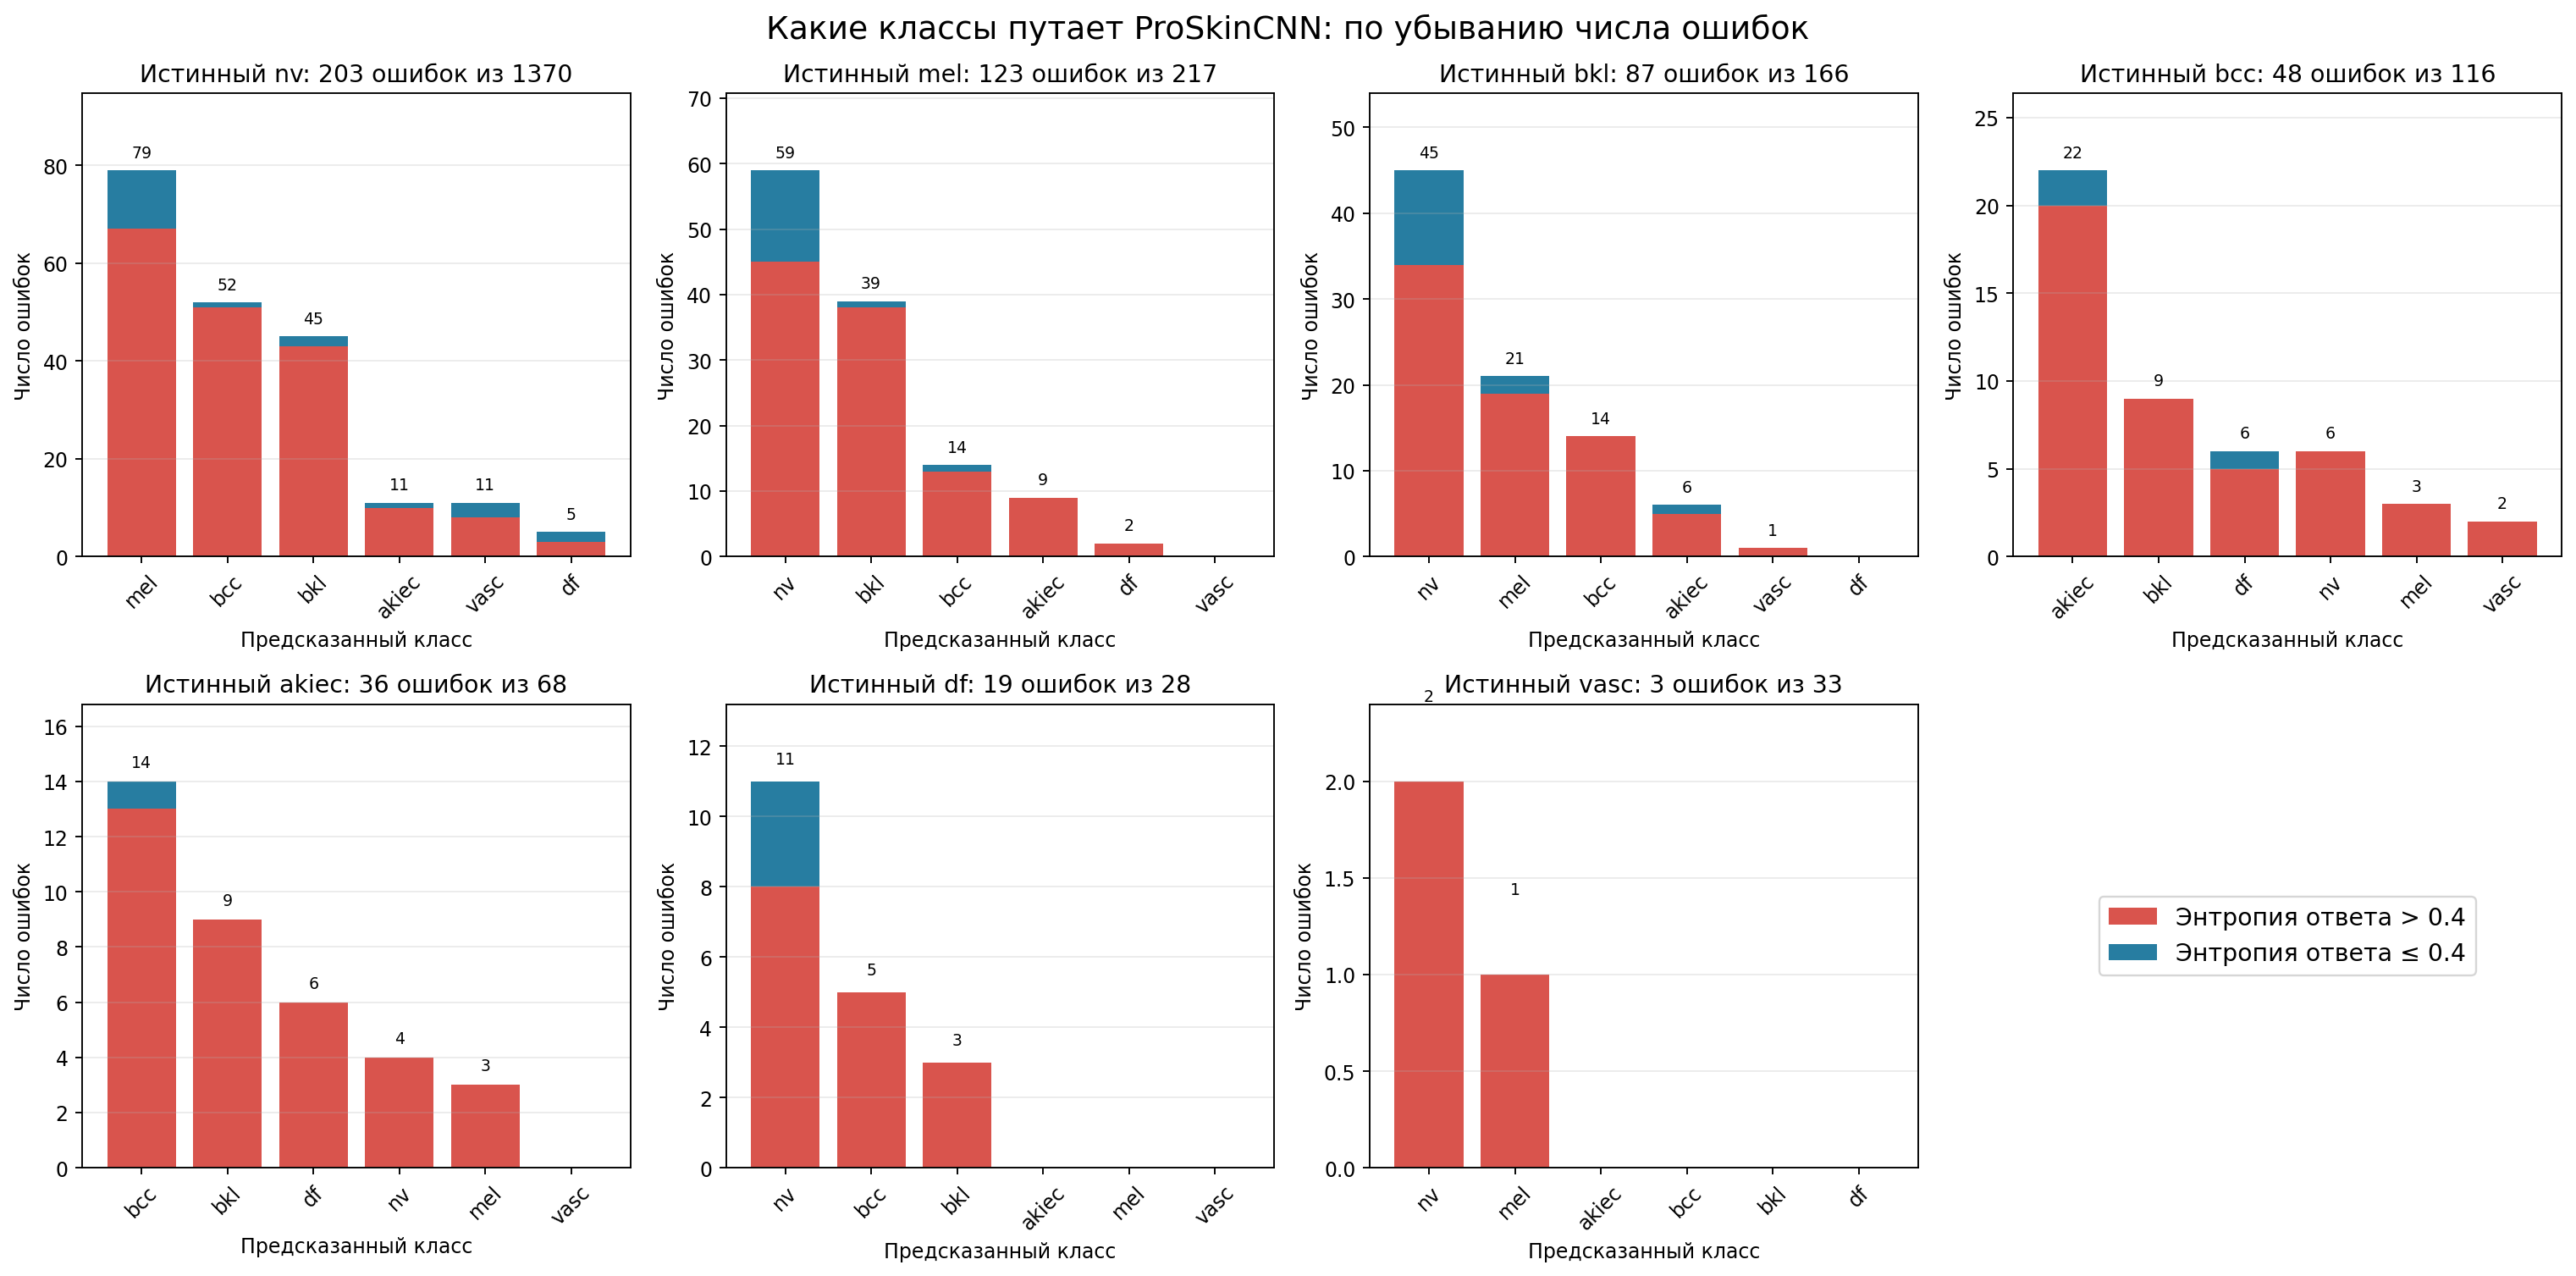

Снимков: 1998; ошибок: 519; при энтропии > 0.4: 461
Самые частые направления ошибок:
true_class predicted_class  errors_total  errors_high_entropy  errors_low_entropy
        nv             mel            79                   67                  12
       mel              nv            59                   45                  14
        nv             bcc            52                   51                   1
        nv             bkl            45                   43                   2
       bkl              nv            45                   34                  11
       mel             bkl            39                   38                   1
       bcc           akiec            22                   20                   2
       bkl             mel            21                   19                   2
       mel             bcc            14                   13                   1
       bkl             bcc            14                   14                   0


In [ ]:
import os
from pathlib import Path

import matplotlib.pyplot as plt
from matplotlib.patches import Patch
import numpy as np
import pandas as pd

THRESHOLD = 0.4
validation = pd.read_csv('graphics/entropy/validation_entropy_n48.csv')
validation['correct'] = validation['correct'].astype(bool)
wrong = validation[~validation['correct']].copy()
class_error_counts = wrong['true_class'].value_counts()
classes = sorted(validation['true_class'].unique(),
                 key=lambda name: (-int(class_error_counts.get(name, 0)), name))

pairs = []
for true_class in classes:
    for predicted_class in classes:
        if predicted_class == true_class:
            continue
        subset = wrong[(wrong['true_class'] == true_class) & (wrong['predicted_class'] == predicted_class)]
        high_count = int((subset['output_normalized'] > THRESHOLD).sum())
        pairs.append({
            'true_class': true_class,
            'predicted_class': predicted_class,
            'errors_total': len(subset),
            'errors_high_entropy': high_count,
            'errors_low_entropy': len(subset) - high_count,
        })
pair_counts = pd.DataFrame(pairs)
pair_counts = pd.concat(
    [pair_counts[pair_counts['true_class'] == name].sort_values(
        ['errors_total', 'predicted_class'], ascending=[False, True])
     for name in classes],
    ignore_index=True,
)
assert pair_counts['errors_total'].sum() == len(wrong)

output_dir = Path(os.environ.get('ENTROPY_OUTPUT_DIR', 'graphics/entropy')) / 'confusions'
output_dir.mkdir(parents=True, exist_ok=True)
pair_counts.to_csv(output_dir / 'confusion_pairs_n48.csv', index=False)

high_color = '#d9544d'
low_color = '#277da1'
legend_items = [
    Patch(facecolor=high_color, label='Энтропия ответа > 0.4'),
    Patch(facecolor=low_color, label='Энтропия ответа ≤ 0.4'),
]


def draw_confusions(ax, true_class):
    subset = pair_counts[pair_counts['true_class'] == true_class].sort_values(
        ['errors_total', 'predicted_class'], ascending=[False, True])
    x = np.arange(len(subset))
    high = subset['errors_high_entropy'].to_numpy()
    low = subset['errors_low_entropy'].to_numpy()
    total = subset['errors_total'].to_numpy()
    ax.bar(x, high, color=high_color)
    ax.bar(x, low, bottom=high, color=low_color)
    for pos, count in zip(x, total):
        if count:
            ax.text(pos, count + max(0.4, total.max() * 0.025), str(count),
                    ha='center', va='bottom', fontsize=8)
    n_true = int((validation['true_class'] == true_class).sum())
    ax.set_title(f'Истинный {true_class}: {total.sum()} ошибок из {n_true}')
    ax.set_xticks(x, subset['predicted_class'], rotation=45)
    ax.set_ylabel('Число ошибок')
    ax.set_xlabel('Предсказанный класс')
    ax.set_ylim(0, max(1, total.max() * 1.2))
    ax.grid(axis='y', alpha=0.25)


fig, axes = plt.subplots(2, 4, figsize=(18, 9))
for ax, true_class in zip(axes.flat, classes):
    draw_confusions(ax, true_class)
axes.flat[-1].axis('off')
axes.flat[-1].legend(handles=legend_items, loc='center', fontsize=12)
fig.suptitle('Какие классы путает ProSkinCNN: по убыванию числа ошибок', fontsize=16)
fig.tight_layout()
fig.savefig(output_dir / 'confusion_overview_n48.png', dpi=170, bbox_inches='tight')
plt.show()

for true_class in classes:
    fig, ax = plt.subplots(figsize=(7, 4))
    draw_confusions(ax, true_class)
    ax.legend(handles=legend_items)
    fig.tight_layout()
    fig.savefig(output_dir / f'confusion_true_{true_class}_n48.png', dpi=170)
    plt.close(fig)

print(f'Снимков: {len(validation)}; ошибок: {len(wrong)}; '
      f'при энтропии > {THRESHOLD}: {(wrong.output_normalized > THRESHOLD).sum()}')
print('Самые частые направления ошибок:')
print(pair_counts.sort_values('errors_total', ascending=False).head(10).to_string(index=False))


### Наблюдения по диаграммам

Чаще всего встречаются направления `nv → mel` (79), `mel → nv` (59), `nv → bcc` (52), `nv → bkl` (45), `bkl → nv` (45) и `mel → bkl` (39). Это **число** ошибок, а не вероятность ошибки: размер каждого класса разный.

Несколько важных уточнений к чтению предыдущего графика. При энтропии ответа `> 0.4` модель правильно распознала 6 из 22 снимков `df` и 70 из 177 снимков `mel`, поэтому «никогда не определит» слишком сильный вывод. При энтропии `≤ 0.4` среди 30 ответов модели `vasc` было 3 ошибки; абсолютной надёжности здесь нет. Для `akiec` в этой зоне всего 2 истинных снимка, поэтому сравнение «независимо от энтропии» по нему пока неустойчиво.

Эти направления помогут выбрать задачи для дополнительной модели, но эффективность шести отдельных моделей ещё не проверена: потребуется сравнить их с базовой на отложенных снимках, включая ошибочные маршрутизации между моделями.


## Шесть независимых моделей ProSkin: проверка гипотезы

По направлениям ошибок базовой модели обучаем шесть **отдельных** моделей с той же архитектурой ProSkinCNN. Каждая получает исходные снимки HAM10000 с настоящими диагнозами; исключённые классы полностью отсутствуют в её обучении и выходном слое. B и C имеют одинаковые пять классов, но обучаются независимо с разными случайными инициализациями. Связь с графиками ошибок: A — `nv`, B — `mel`, C — `bkl`, D — `bcc`, E — `akiec`, F — `df`.

Разделение 80/20 сделано по `lesion_id` с `random_state=42`, как при проверке базовой модели. Здесь используются только **исходные** снимки: случайные повороты, обрезка, отражение и изменение цвета применяются на лету только при обучении. Оптимизатор AdamW (`lr=10⁻³`, `weight_decay=10⁻⁴`), взвешенная кросс-энтропия, cosine scheduler, до 20 эпох с ранней остановкой после пяти эпох без улучшения macro F1. Для каждой модели сохранены лучшие веса по проверочному macro F1, последние веса, история CSV, конфигурация JSON, график и схема в `my-models/specialists/` и `graphics/proskin-specialists/`. Для воспроизведения: `python train_proskin_specialists.py --epochs 20 --patience 5`.

**Ограничение гипотезы:** показатели ниже рассчитаны только на снимках классов, доступных соответствующему специалисту. Они не измеряют качество всей системы из семи классов: правило выбора специалиста и поведение на исключённых диагнозах нужно проверять отдельно, на независимой выборке пациентов.


### ProSkinA: истинный класс `nv`

Проверка частых ошибок истинного `nv`. Выходные классы: все классы, кроме `df`. Веса с наилучшим macro F1: [`ProSkinA_best.pth`](my-models/specialists/ProSkinA_best.pth), метки и настройки: [`ProSkinA_config.json`](my-models/specialists/ProSkinA_config.json).

**Структура сети**

![Структура ProSkinA](graphics/proskin-specialists/ProSkinA_architecture.png)

**Ход обучения**

![Обучение ProSkinA](graphics/proskin-specialists/ProSkinA_training.png)


### ProSkinB: истинный класс `mel`

Проверка частых ошибок истинного `mel`. Выходные классы: все классы, кроме `df` и `vasc`. Веса с наилучшим macro F1: [`ProSkinB_best.pth`](my-models/specialists/ProSkinB_best.pth), метки и настройки: [`ProSkinB_config.json`](my-models/specialists/ProSkinB_config.json).

**Структура сети**

![Структура ProSkinB](graphics/proskin-specialists/ProSkinB_architecture.png)

**Ход обучения**

![Обучение ProSkinB](graphics/proskin-specialists/ProSkinB_training.png)


### ProSkinC: истинный класс `bkl`

Независимый запуск для ошибок истинного `bkl`; набор классов совпадает с B. Выходные классы: все классы, кроме `df` и `vasc`. Веса с наилучшим macro F1: [`ProSkinC_best.pth`](my-models/specialists/ProSkinC_best.pth), метки и настройки: [`ProSkinC_config.json`](my-models/specialists/ProSkinC_config.json).

**Структура сети**

![Структура ProSkinC](graphics/proskin-specialists/ProSkinC_architecture.png)

**Ход обучения**

![Обучение ProSkinC](graphics/proskin-specialists/ProSkinC_training.png)


### ProSkinD: истинный класс `bcc`

Проверка частых ошибок истинного `bcc`. Выходные классы: все классы, кроме `mel` и `vasc`. Веса с наилучшим macro F1: [`ProSkinD_best.pth`](my-models/specialists/ProSkinD_best.pth), метки и настройки: [`ProSkinD_config.json`](my-models/specialists/ProSkinD_config.json).

**Структура сети**

![Структура ProSkinD](graphics/proskin-specialists/ProSkinD_architecture.png)

**Ход обучения**

![Обучение ProSkinD](graphics/proskin-specialists/ProSkinD_training.png)


### ProSkinE: истинный класс `akiec`

Проверка ошибок истинного `akiec`. Выходные классы: все классы, кроме `vasc`. Веса с наилучшим macro F1: [`ProSkinE_best.pth`](my-models/specialists/ProSkinE_best.pth), метки и настройки: [`ProSkinE_config.json`](my-models/specialists/ProSkinE_config.json).

**Структура сети**

![Структура ProSkinE](graphics/proskin-specialists/ProSkinE_architecture.png)

**Ход обучения**

![Обучение ProSkinE](graphics/proskin-specialists/ProSkinE_training.png)


### ProSkinF: истинный класс `df`

Четырёхклассовая модель для ошибок истинного `df`. Выходные классы: только `df`, `nv`, `bcc`, `bkl`. Веса с наилучшим macro F1: [`ProSkinF_best.pth`](my-models/specialists/ProSkinF_best.pth), метки и настройки: [`ProSkinF_config.json`](my-models/specialists/ProSkinF_config.json).

**Структура сети**

![Структура ProSkinF](graphics/proskin-specialists/ProSkinF_architecture.png)

**Ход обучения**

![Обучение ProSkinF](graphics/proskin-specialists/ProSkinF_training.png)


In [ ]:
from pathlib import Path
import json
import pandas as pd

model_dir = Path('my-models/specialists')
rows = []
for letter in 'ABCDEF':
    name = f'ProSkin{letter}'
    path = model_dir / f'{name}_config.json'
    if not path.exists():
        rows.append({'Модель': name, 'Статус': 'обучение ещё не завершено'})
        continue
    info = json.loads(path.read_text())
    rows.append({
        'Модель': name,
        'Классы': ', '.join(info['classes']),
        'Обучение / проверка': f"{info['train_images']} / {info['val_images']}",
        'Лучшая эпоха': info.get('best_epoch'),
        'Эпох выполнено': info.get('epochs_run'),
        'Macro F1': info.get('best_val_macro_f1'),
        'Веса': str(model_dir / f'{name}_best.pth') if (model_dir / f'{name}_best.pth').exists() else None,
    })
display(pd.DataFrame(rows))


## Каскад ProSkin: проверка на тесте ISIC 2018

Сравниваем базовую сеть и каскад на одних и тех же **1512 снимках официального теста ISIC 2018 Task 3**. Идентификаторы снимков теста и HAM10000 не пересекаются. Порог задаём заранее и используем сохранённые чекпойнты специалистов с лучшим валидационным macro F1. [Официальные данные ISIC 2018](https://challenge.isic-archive.com/data/#2018).

### Главный результат

| Метрика | ProSkin | Каскад |
|---|---:|---:|
| **Macro F1 по семи классам** | **0,487** | **0,364** |
| Weighted F1 | 0,687 | 0,577 |
| Accuracy | 67,92% | 54,30% |
| Ошибки | 485 | 691 |

**Macro F1 снизился на 0,123 (12.25 п. п.)**. Специалисты обработали 933 снимков (61,71%). Каскад поменял класс на 536 снимках, исправив 89 ошибок и добавив 295 новых. F1 снизился у каждого из семи классов.

### Правило выбора модели

Базовая ProSkin выдаёт семь вероятностей. Вычисляем их энтропию Шеннона и делим на `log₂ 7`. При значении ниже 0,3 сохраняем ответ ProSkin. При значении 0,3 и выше запускаем специалиста, определённого **предсказанным** классом: `nv → A`, `mel → B`, `bkl → C`, `bcc → D`, `akiec → E`, `df → F`. Ответ `vasc` всегда сохраняется. Если специалист запущен, его класс становится итоговым. При вычислении общего macro F1 обе системы оцениваются по одному итоговому классу для каждого снимка.

| Источник итогового ответа | Снимки | Класс изменился | Ошибка исправлена | Добавилась ошибка |
|---|---:|---:|---:|---:|
| ProSkin | 579 | 0 | 0 | 0 |
| ProSkinA | 360 | 285 | 35 | 214 |
| ProSkinB | 166 | 46 | 7 | 14 |
| ProSkinC | 192 | 62 | 19 | 21 |
| ProSkinD | 117 | 57 | 15 | 15 |
| ProSkinE | 73 | 63 | 11 | 22 |
| ProSkinF | 25 | 23 | 2 | 9 |

Наибольший вклад в снижение точности дал маршрут `nv → A`. Среди 360 переданных снимков он исправил 35 ошибок и добавил 214 новых.

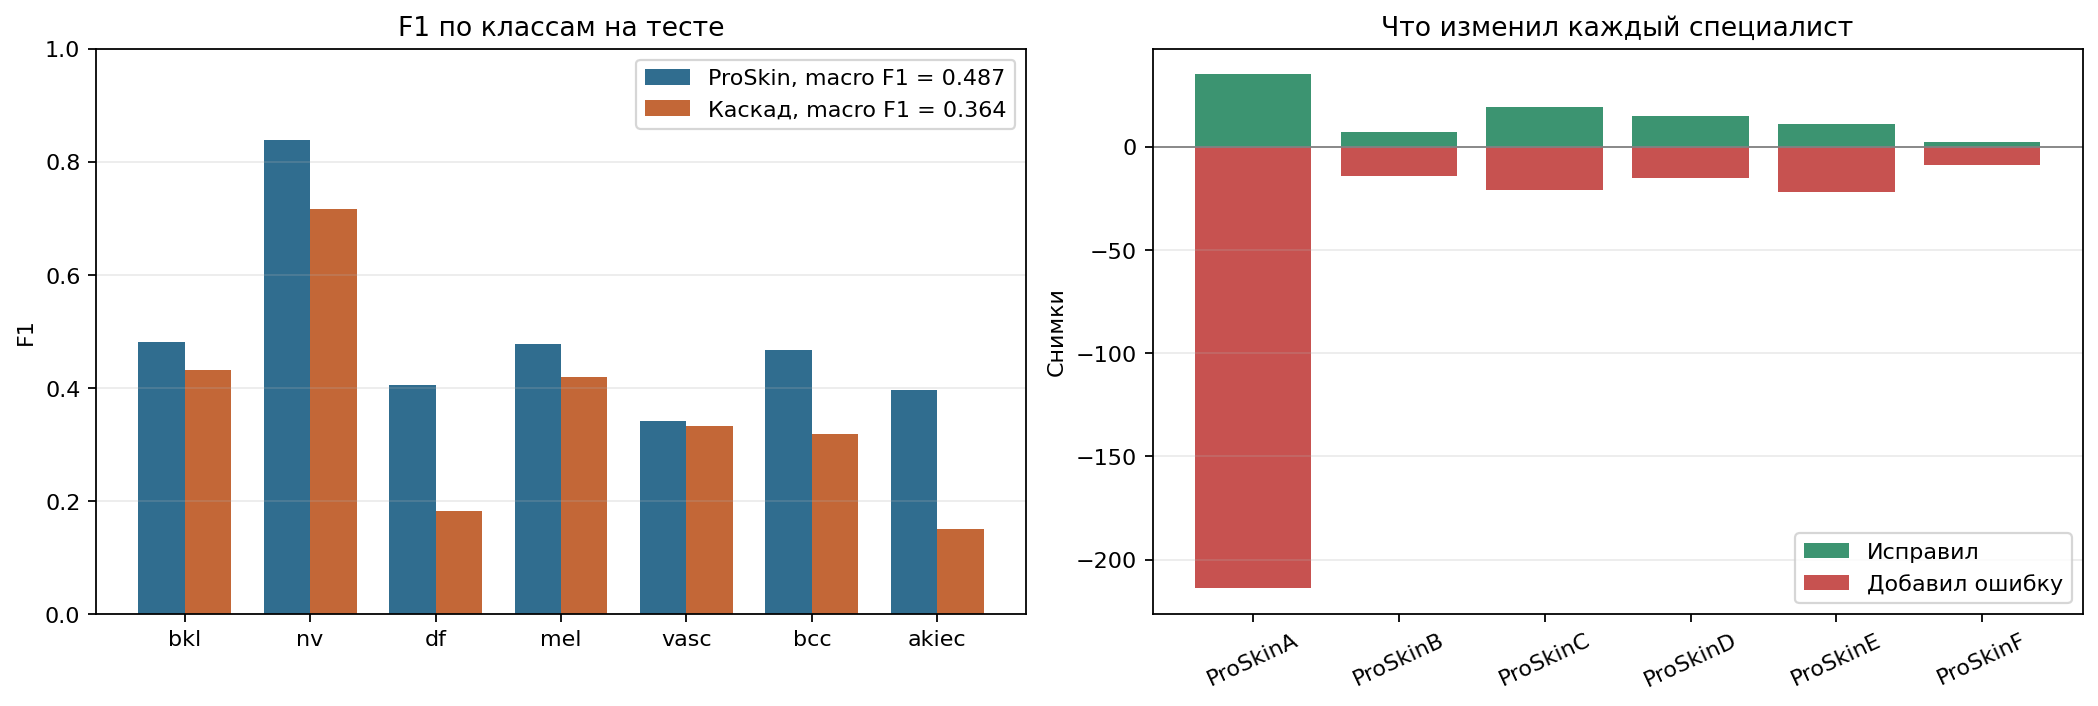

In [ ]:
from IPython.display import Image, display

display(Image(filename='graphics/proskin-cascade/f1_and_routing.png'))

### Какие классы путает каскад

Матрицы рассчитаны по всем тестовым снимкам. На столбчатых диаграммах истинные классы и направления ошибок внутри каждого класса отсортированы по общему числу ошибок.

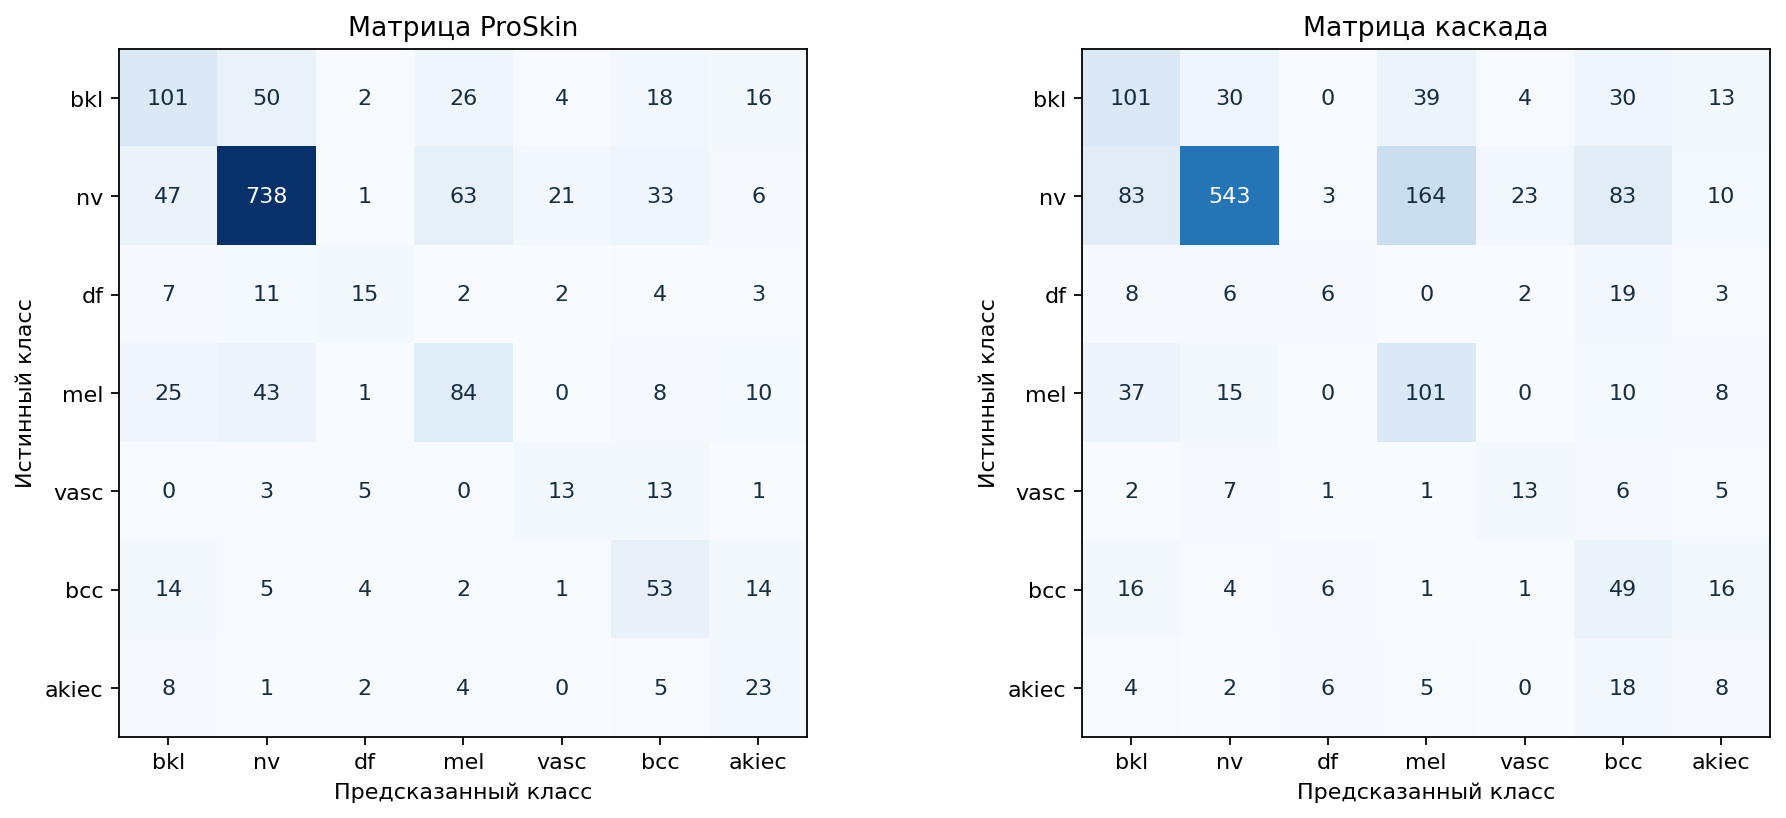

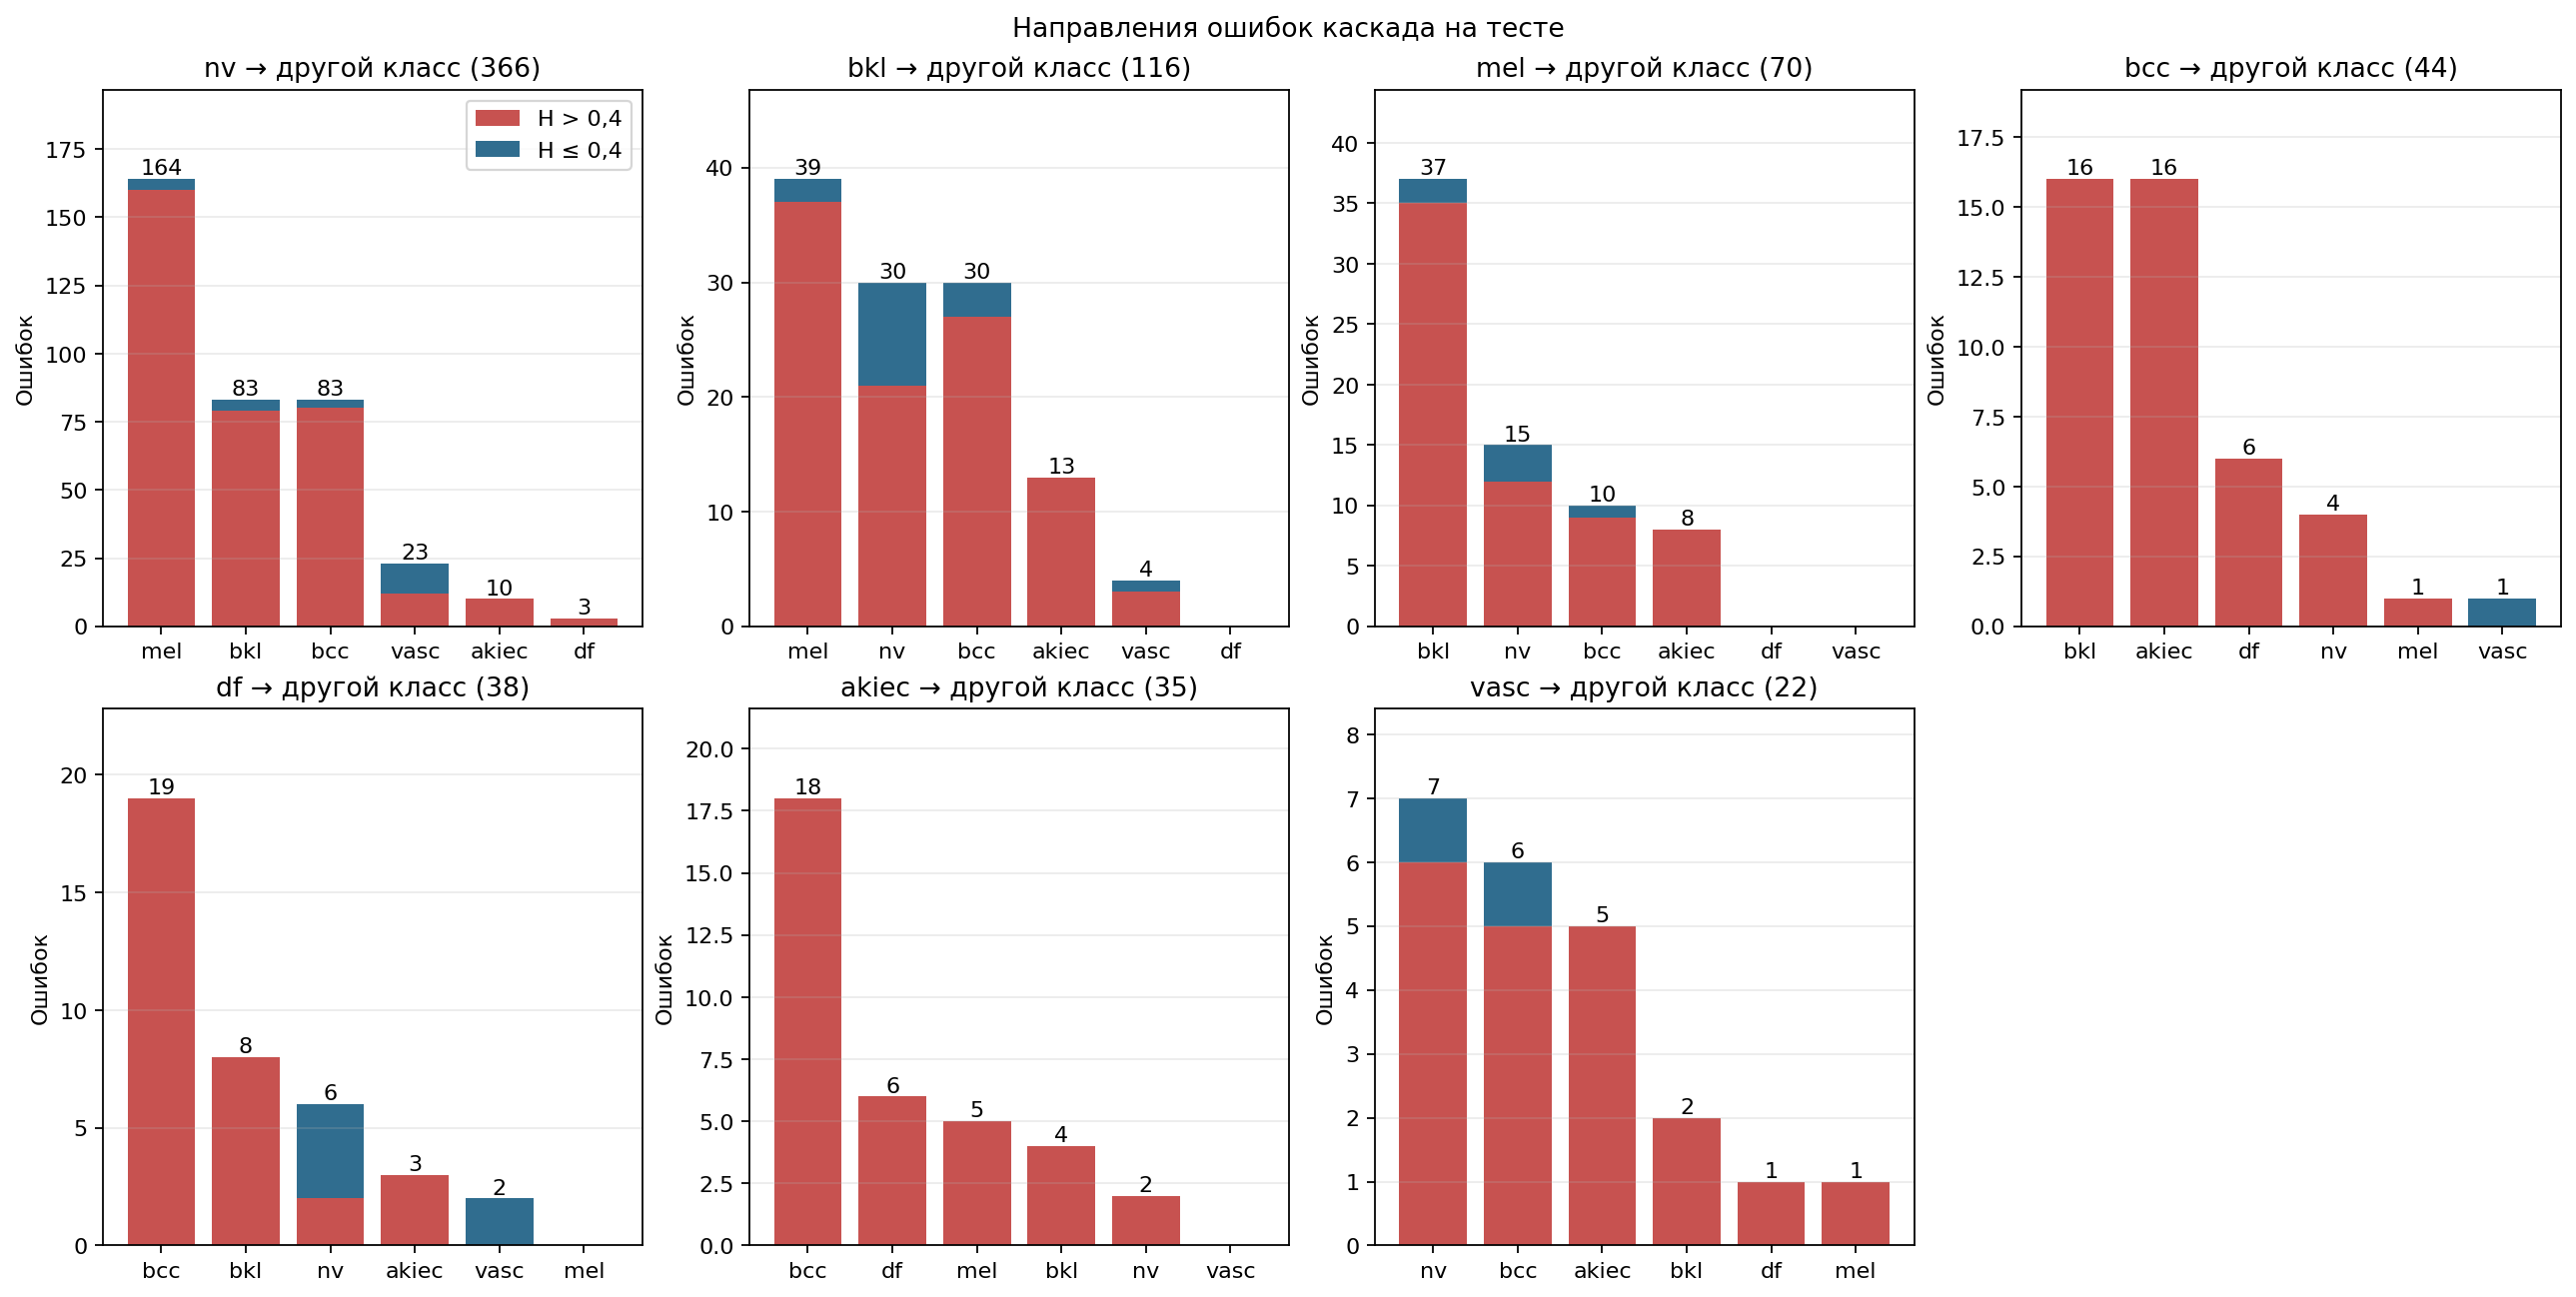

In [ ]:
from IPython.display import Image, display

display(Image(filename='graphics/proskin-cascade/confusion_matrices.png'))
display(Image(filename='graphics/proskin-cascade/error_directions.png'))

### Энтропия итогового ответа и ошибки

Для каждого снимка рассчитываем энтропию вероятностей сети, которая дала итоговый ответ. В таблице и диаграммах с порогом 0,4 делим на `log₂ K`, где `K` — число классов этой сети. Для прямого сравнения распределений, в том числе с энтропией изображения, используем общий делитель `log₂ 7`. На этой шкале средняя энтропия выросла с **0,391** до **0,464**. Энтропия изображения рассчитана по переходам соседних цветов с 48 интервалами на канал.

| Энтропия ответа / log₂ K | Ошибки ProSkin | Ошибки каскада |
|---|---:|---:|
| Ниже 0,3 | 40 / 559 (7,16%) | 42 / 566 (7,42%) |
| От 0,3 до 0,4 включительно | 35 / 127 (27,56%) | 10 / 16 (62,50%) |
| Выше 0,4 | 410 / 826 (49,64%) | 639 / 930 (68,71%) |

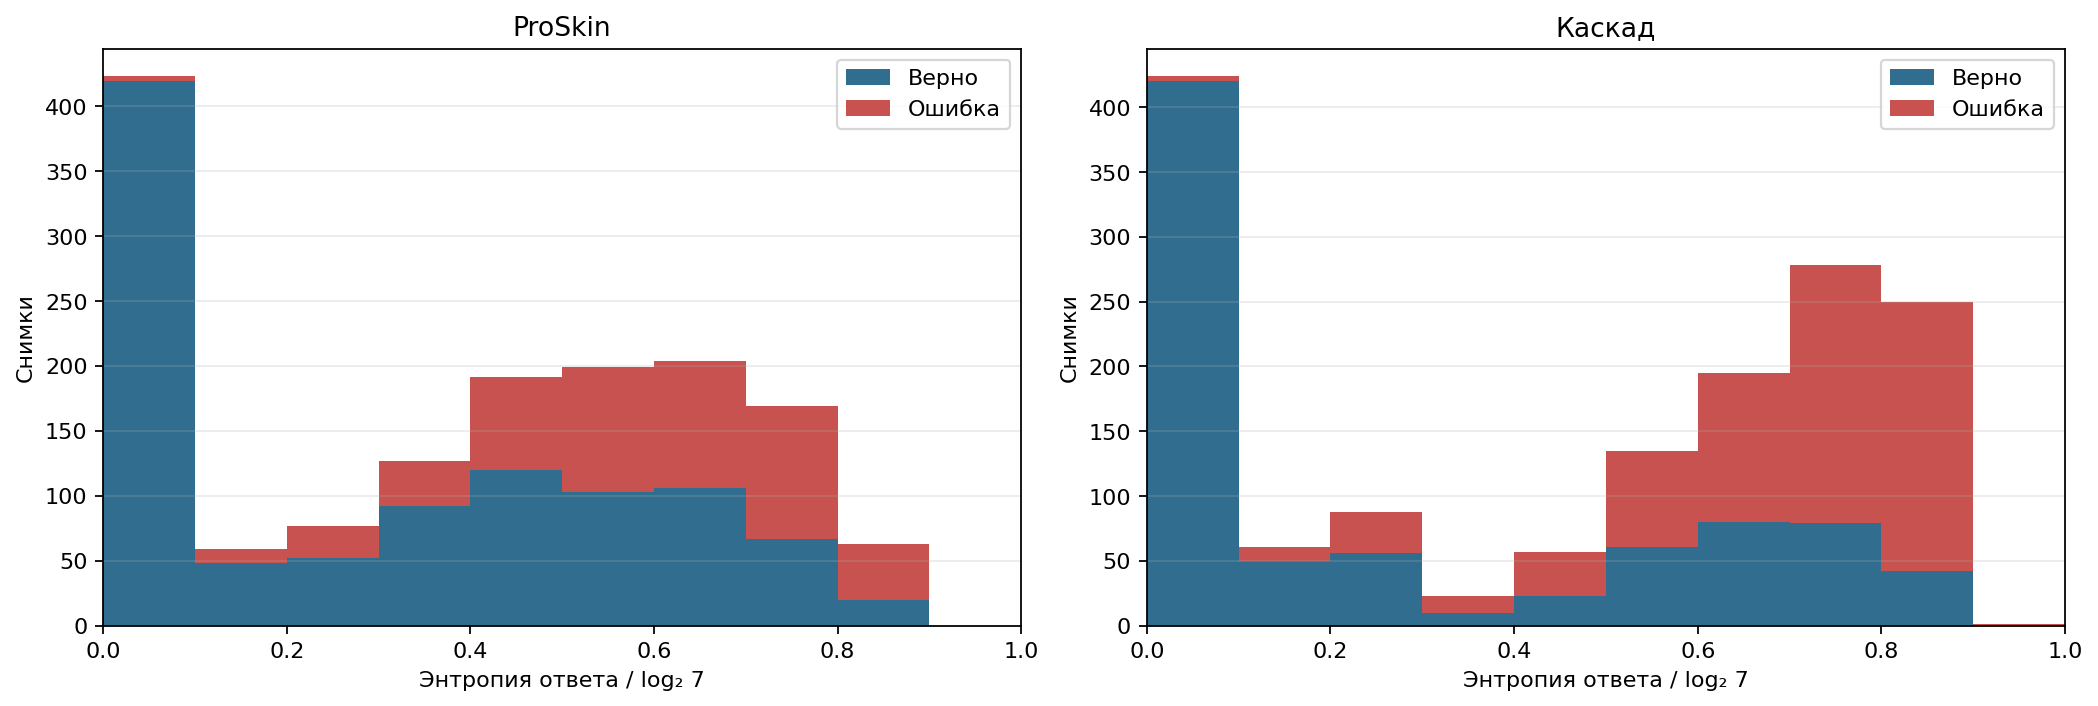

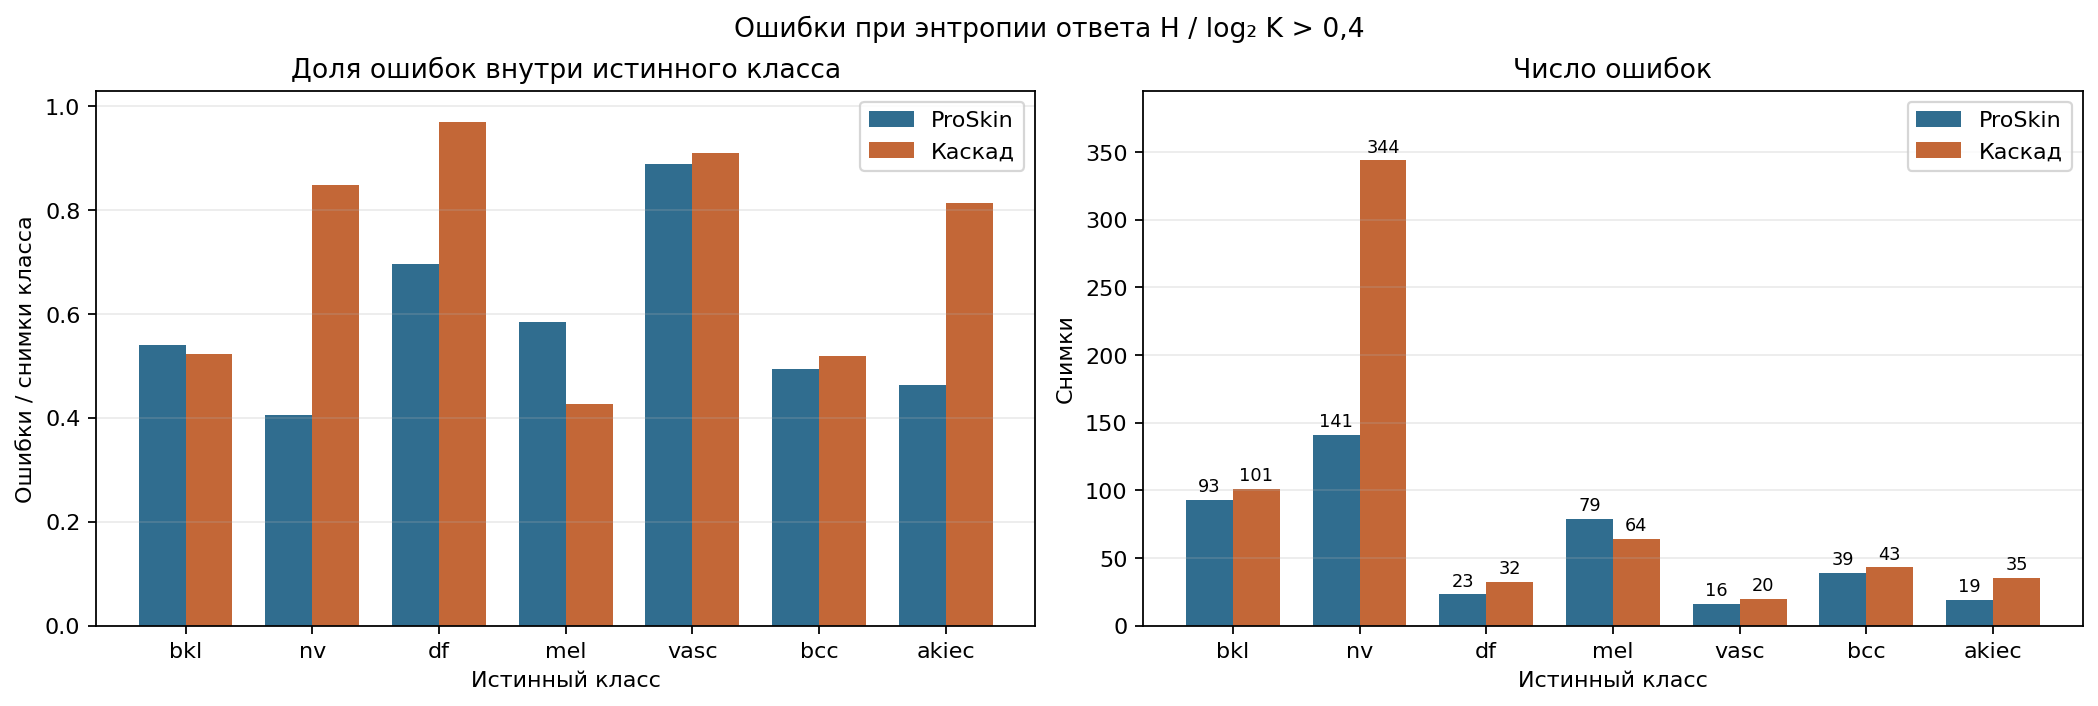

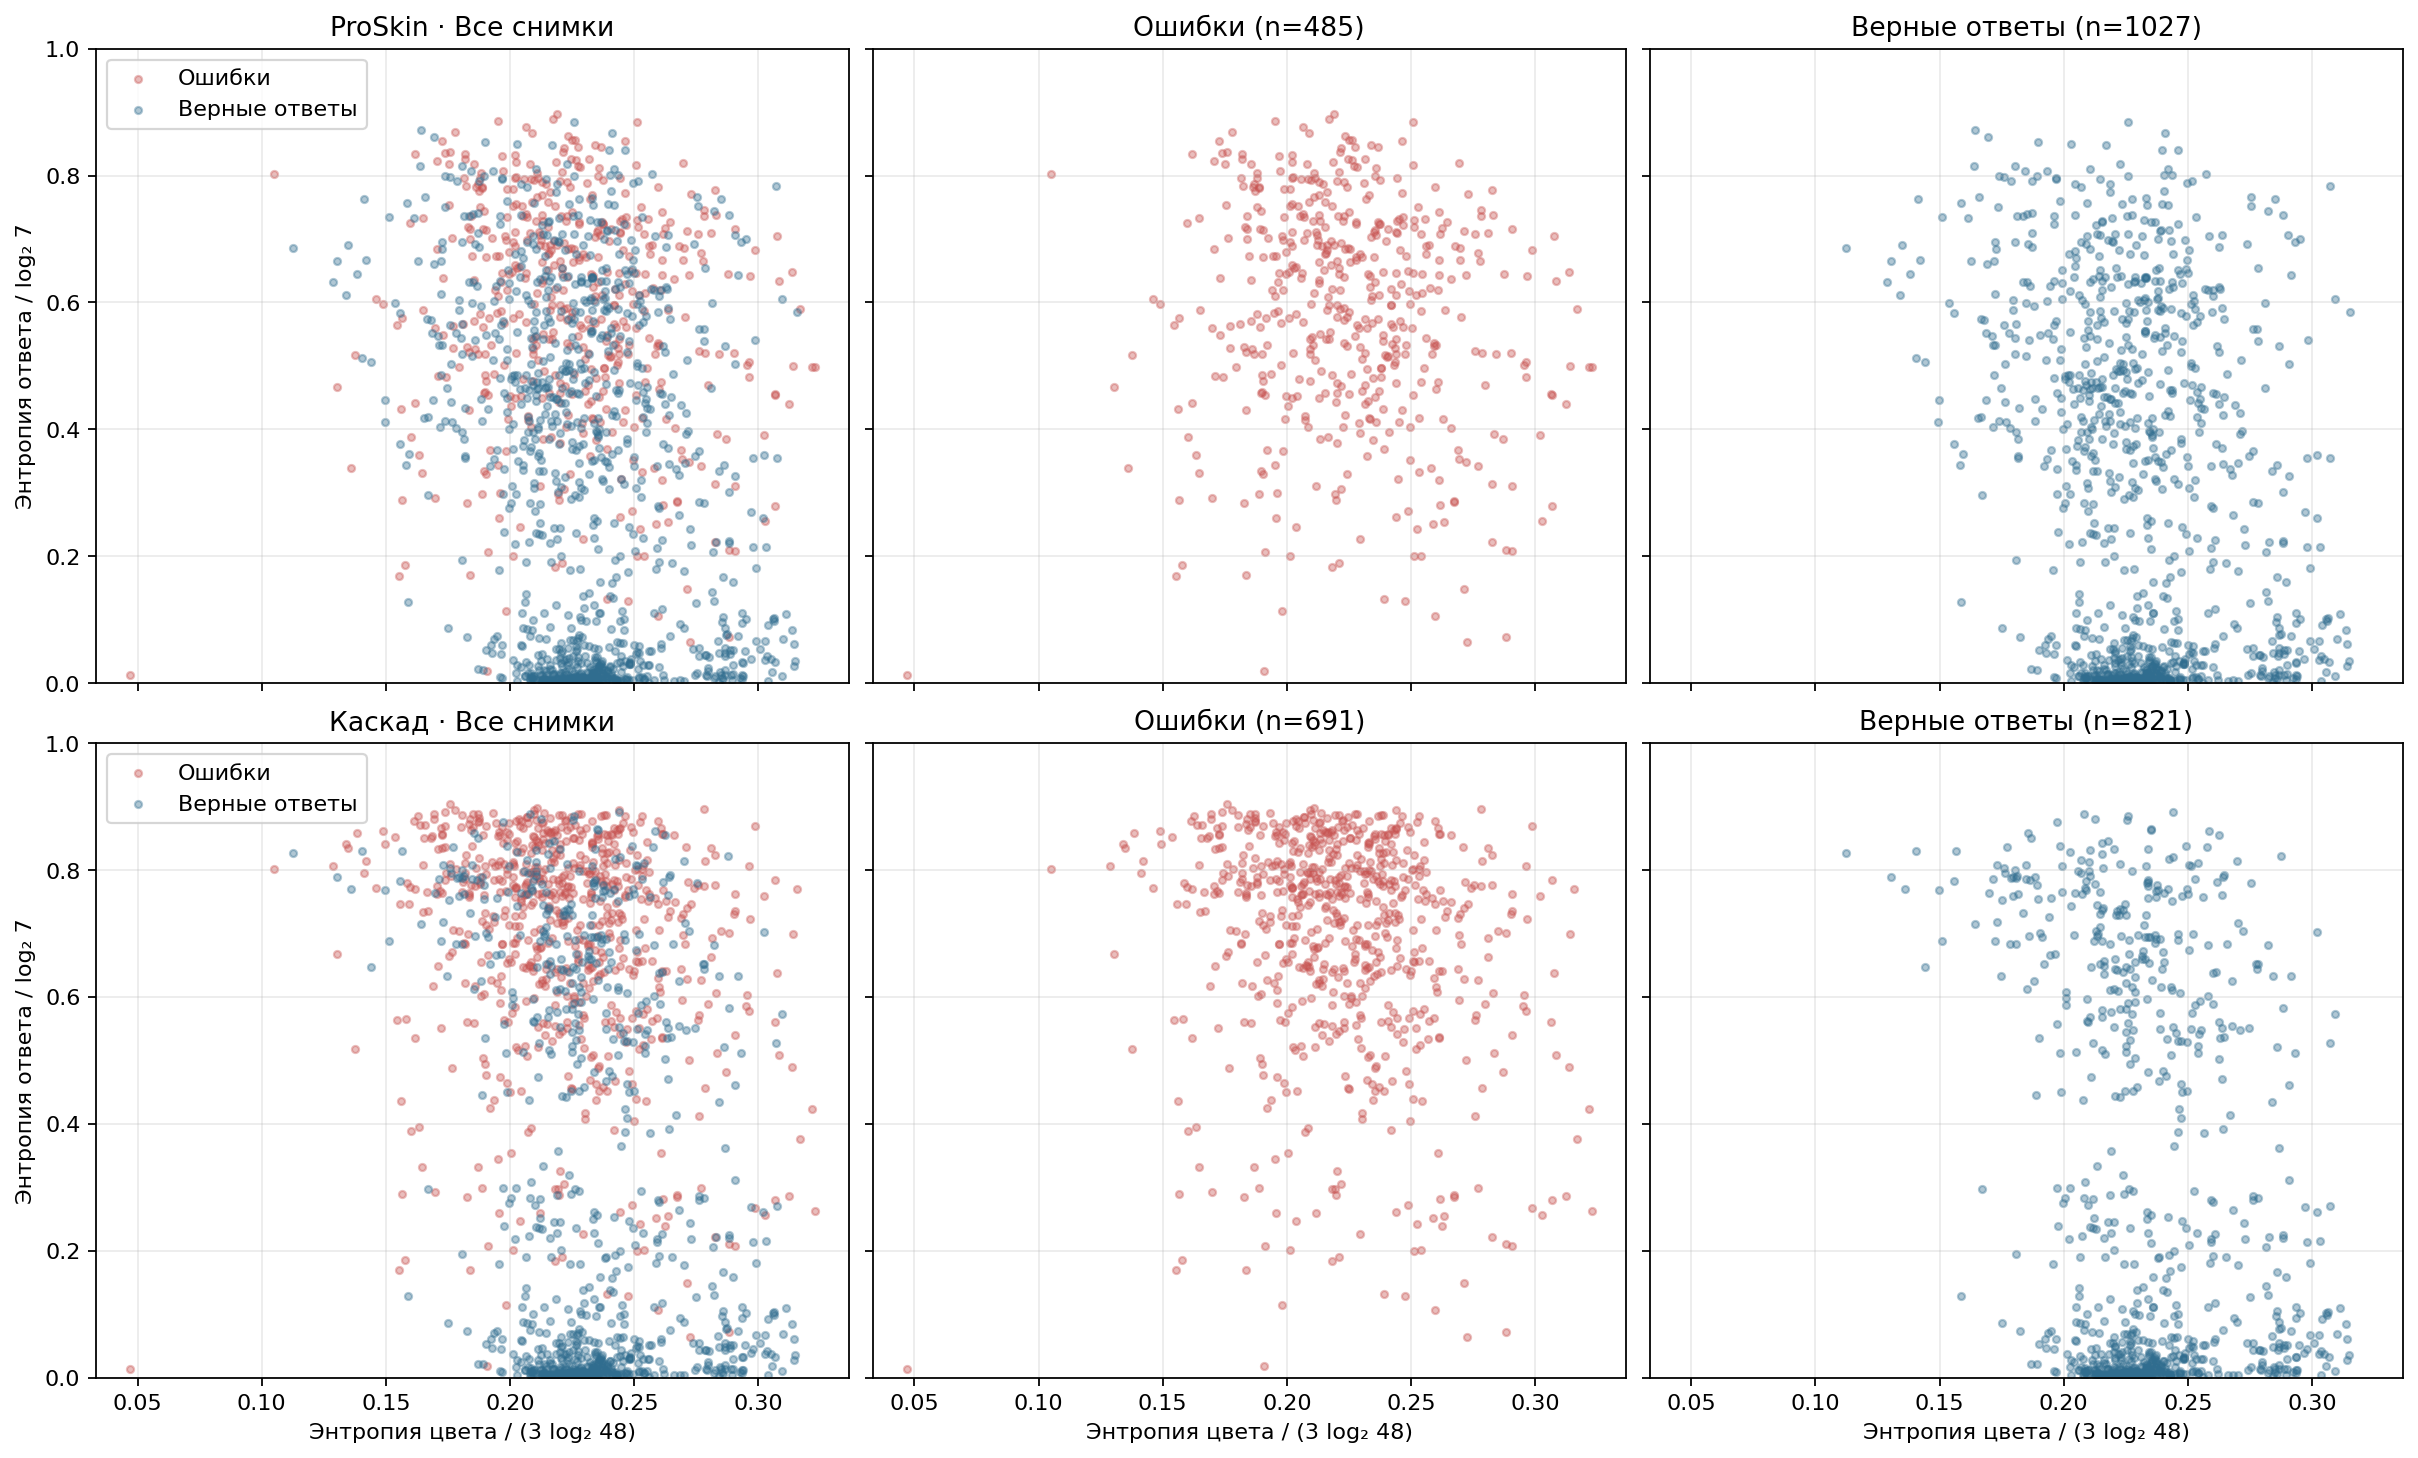

In [ ]:
from IPython.display import Image, display

display(Image(filename='graphics/proskin-cascade/output_entropy.png'))
display(Image(filename='graphics/proskin-cascade/high_entropy_class_errors.png'))
display(Image(filename='graphics/proskin-cascade/image_and_output_entropy.png'))

### Воспроизведение

Команда из папки проекта: `python evaluate_proskin_cascade.py`. Тестовые архивы лежат в `data/isic2018-test/`. В [таблице по снимкам](graphics/proskin-cascade/predictions.csv) записаны оба ответа, маршрут и энтропии. Отдельно сохранены [метрики по классам](graphics/proskin-cascade/per_class_metrics.csv), [ошибки по диапазонам энтропии](graphics/proskin-cascade/entropy_error_rates.csv) и [метрики всего теста](graphics/proskin-cascade/metrics.json).

ISIC 2018 Task 3 Test Input, HAM10000 Dataset © ViDIR Group, Department of Dermatology, Medical University of Vienna. Лицензия CC BY-NC 4.0. [Данные и сведения об авторах](https://challenge.isic-archive.com/data/#2018).

## Каскад ProSkin с порогом 0,4 на тесте ISIC 2018

Повторяем проверку на тех же **1512 тестовых снимках**, с теми же сетями и сохранёнными весами. Повышаем порог маршрутизации: при энтропии ответа базовой ProSkin ниже 0,4 сохраняем её класс. При 0,4 и выше используем `nv → A`, `mel → B`, `bkl → C`, `bcc → D`, `akiec → E`, `df → F` по **предсказанному** классу. Ответ `vasc` всегда оставляем. Итоговый класс и вероятности берём у сети, которая выдала итоговый ответ.

### Сравнение на одном тесте

| Метрика | ProSkin | Каскад 0,3 | Каскад 0,4 |
|---|---:|---:|---:|
| **Macro F1** | 0,487 | 0,364 | 0,376 |
| Weighted F1 | 0,687 | 0,577 | 0,596 |
| Точность, % | 67,92 | 54,30 | 56,42 |
| Число ошибок | 485 | 691 | 659 |

Разница в macro F1 при повышении порога составила **+1,11 п. п.** Разница каскада при 0,4 с базовой моделью составила **-11,14 п. п.** Число передач специалистам изменилось с 933 до 811. При пороге 0,4 каскад исправил 84 ошибок, добавил 258 новых и поменял ответ на 489 снимках.

| Источник итогового ответа | Снимки | Класс изменился | Ошибка исправлена | Добавилась ошибка |
|---|---:|---:|---:|---:|
| ProSkin | 701 | 0 | 0 | 0 |
| ProSkinA | 293 | 249 | 32 | 181 |
| ProSkinB | 145 | 46 | 7 | 14 |
| ProSkinC | 171 | 59 | 19 | 19 |
| ProSkinD | 106 | 51 | 13 | 14 |
| ProSkinE | 72 | 62 | 11 | 21 |
| ProSkinF | 24 | 22 | 2 | 9 |

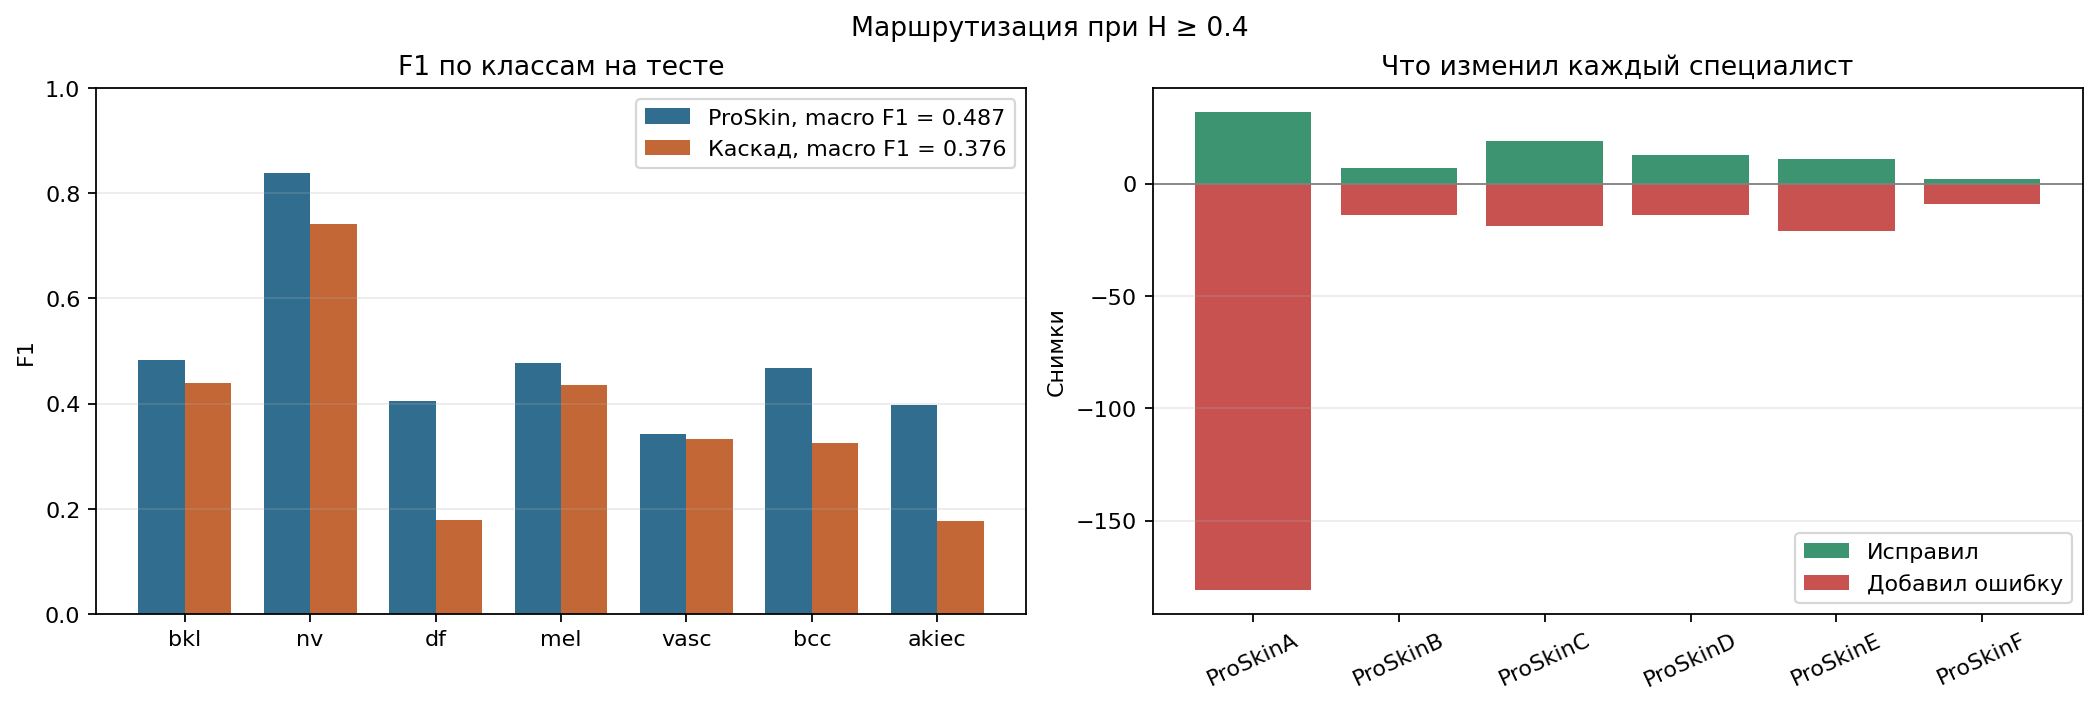

In [ ]:
from IPython.display import Image, display

display(Image(filename='graphics/proskin-cascade-0.4/f1_and_routing.png'))


### Направления ошибок

Матрицы показывают число предсказаний на всех 1512 снимках. На нижних диаграммах каскада истинные классы и направления ошибок отсортированы по общему числу ошибок.

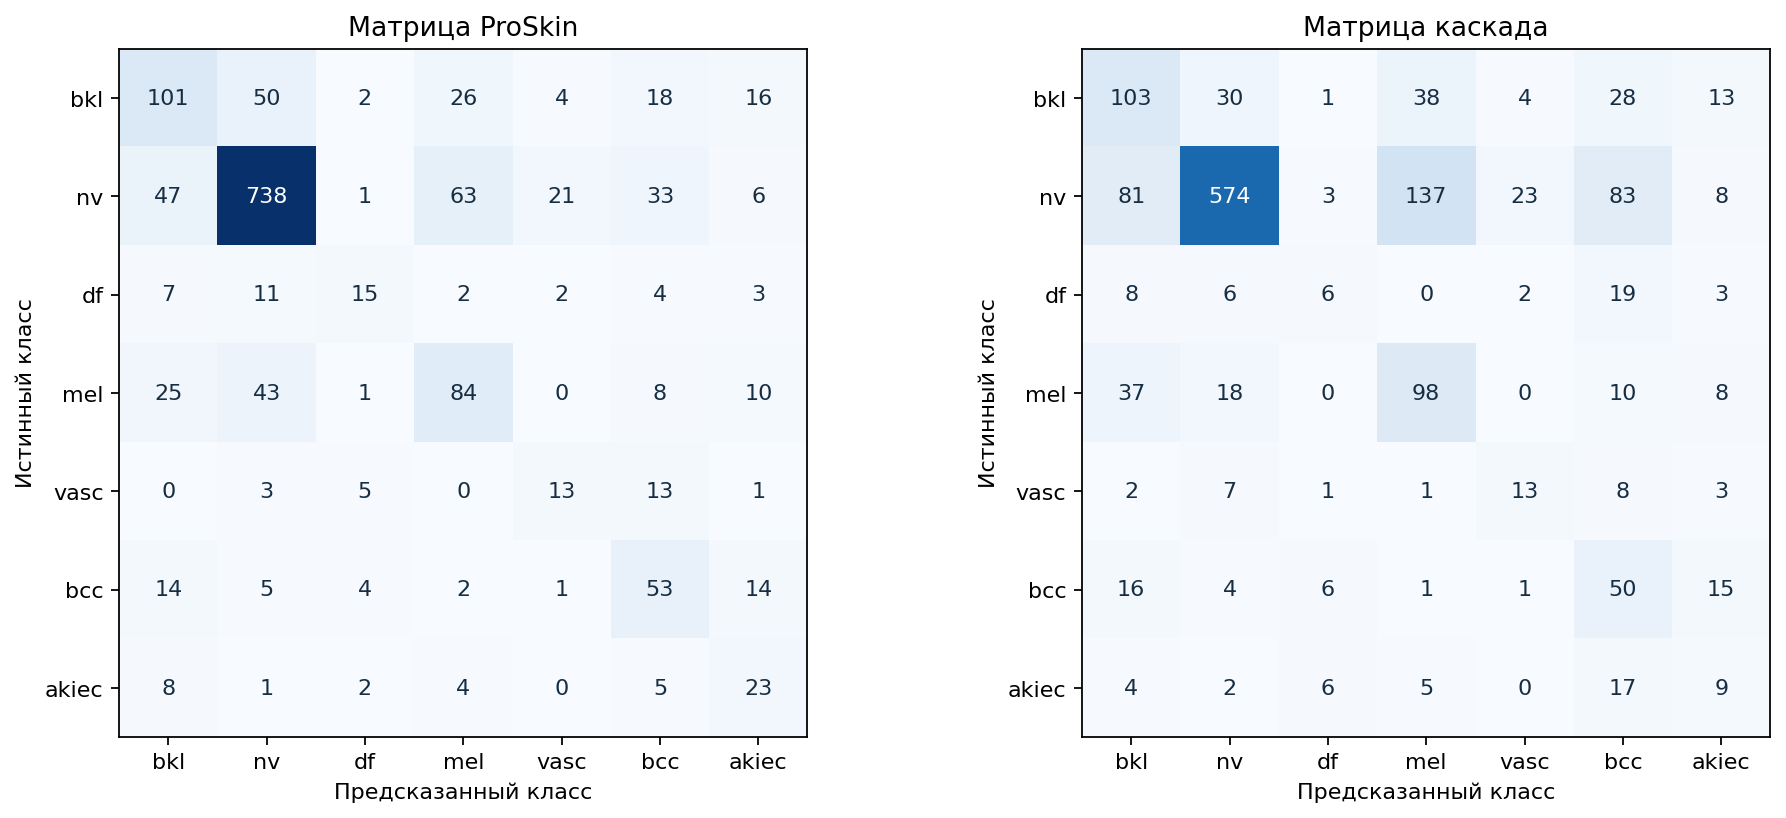

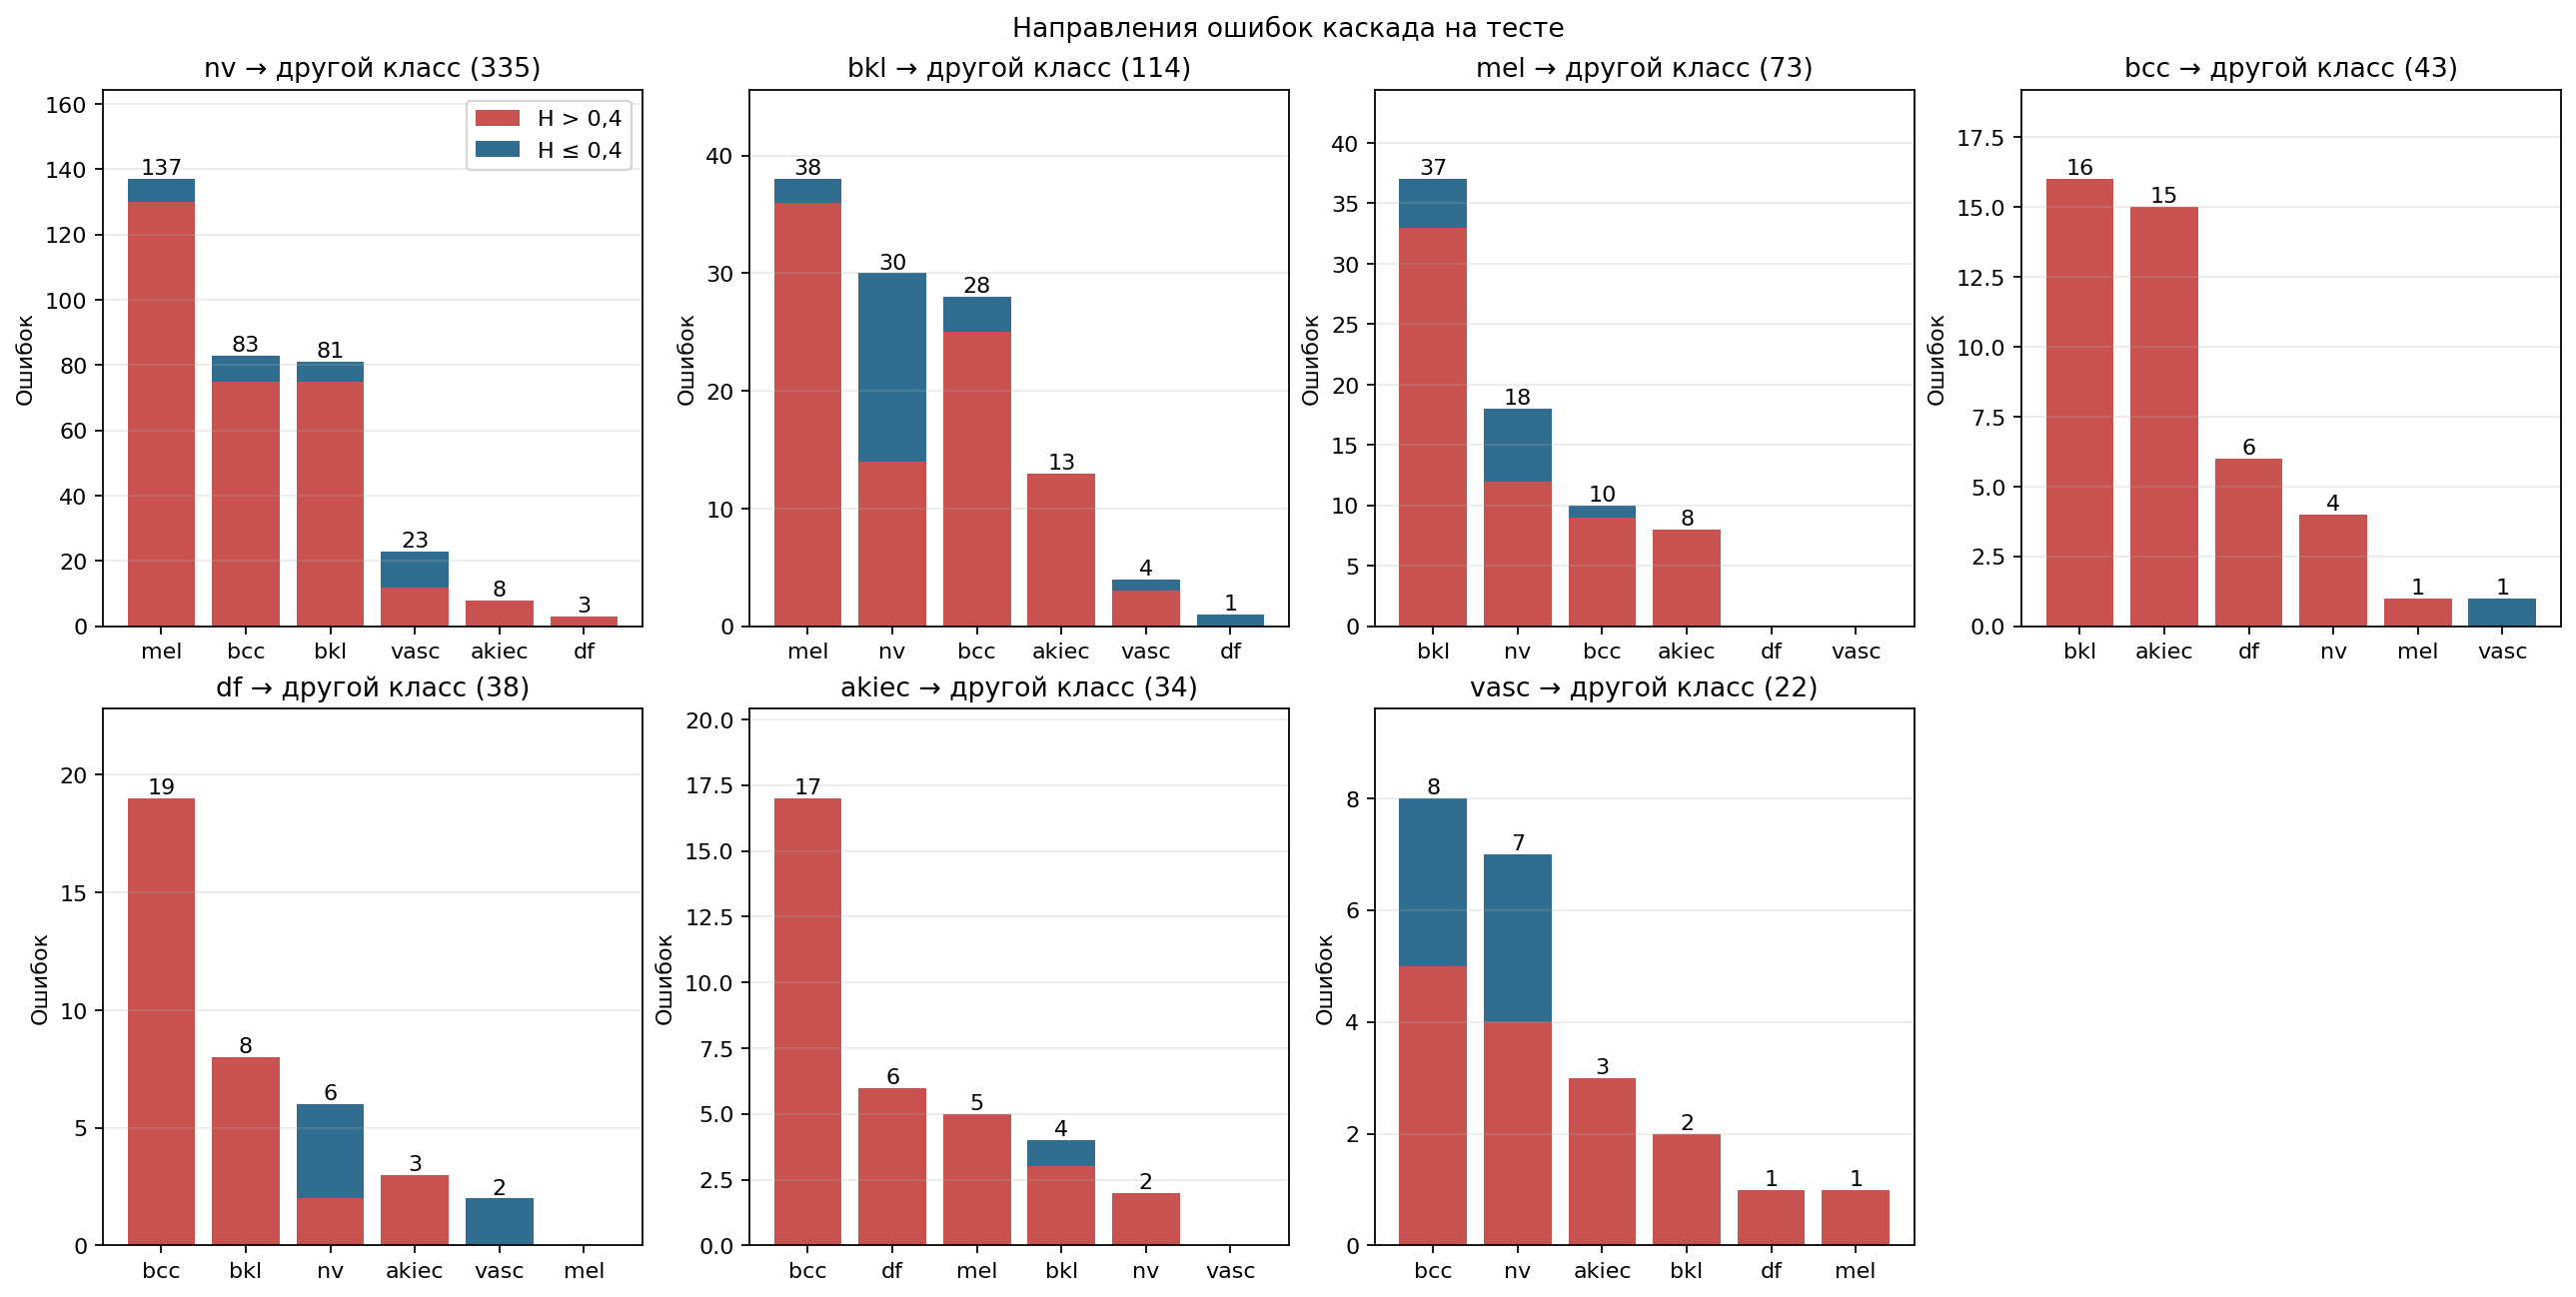

In [ ]:
from IPython.display import Image, display

display(Image(filename='graphics/proskin-cascade-0.4/confusion_matrices.png'))
display(Image(filename='graphics/proskin-cascade-0.4/error_directions.png'))


### Энтропия ответа и ошибки

Группы в таблице определены по итоговой энтропии соответствующей системы, делённой на `log₂ K`, где `K` — число её выходных классов для снимка. При прямом сравнении обеих систем используем общий делитель `log₂ 7`: средняя энтропия ответа равна **0,391** у ProSkin и **0,444** у каскада. Энтропия цвета рассчитана с 48 интервалами на канал.

| Энтропия ответа / log₂ K | Ошибки / снимки у ProSkin | Ошибки / снимки у каскада |
|---|---:|---:|
| Ниже 0,3 | 40 / 559 | 42 / 561 |
| От 0,3 до 0,4 включительно | 35 / 127 | 38 / 133 |
| Выше 0,4 | 410 / 826 | 579 / 818 |

Порог передачи применяется к **ответу базовой модели**. Порог 0,4 на диаграммах ошибок применяется к **итоговому ответу**. Для оценки порога, выбранного по результатам этих двух запусков, потребуется отдельная выборка.

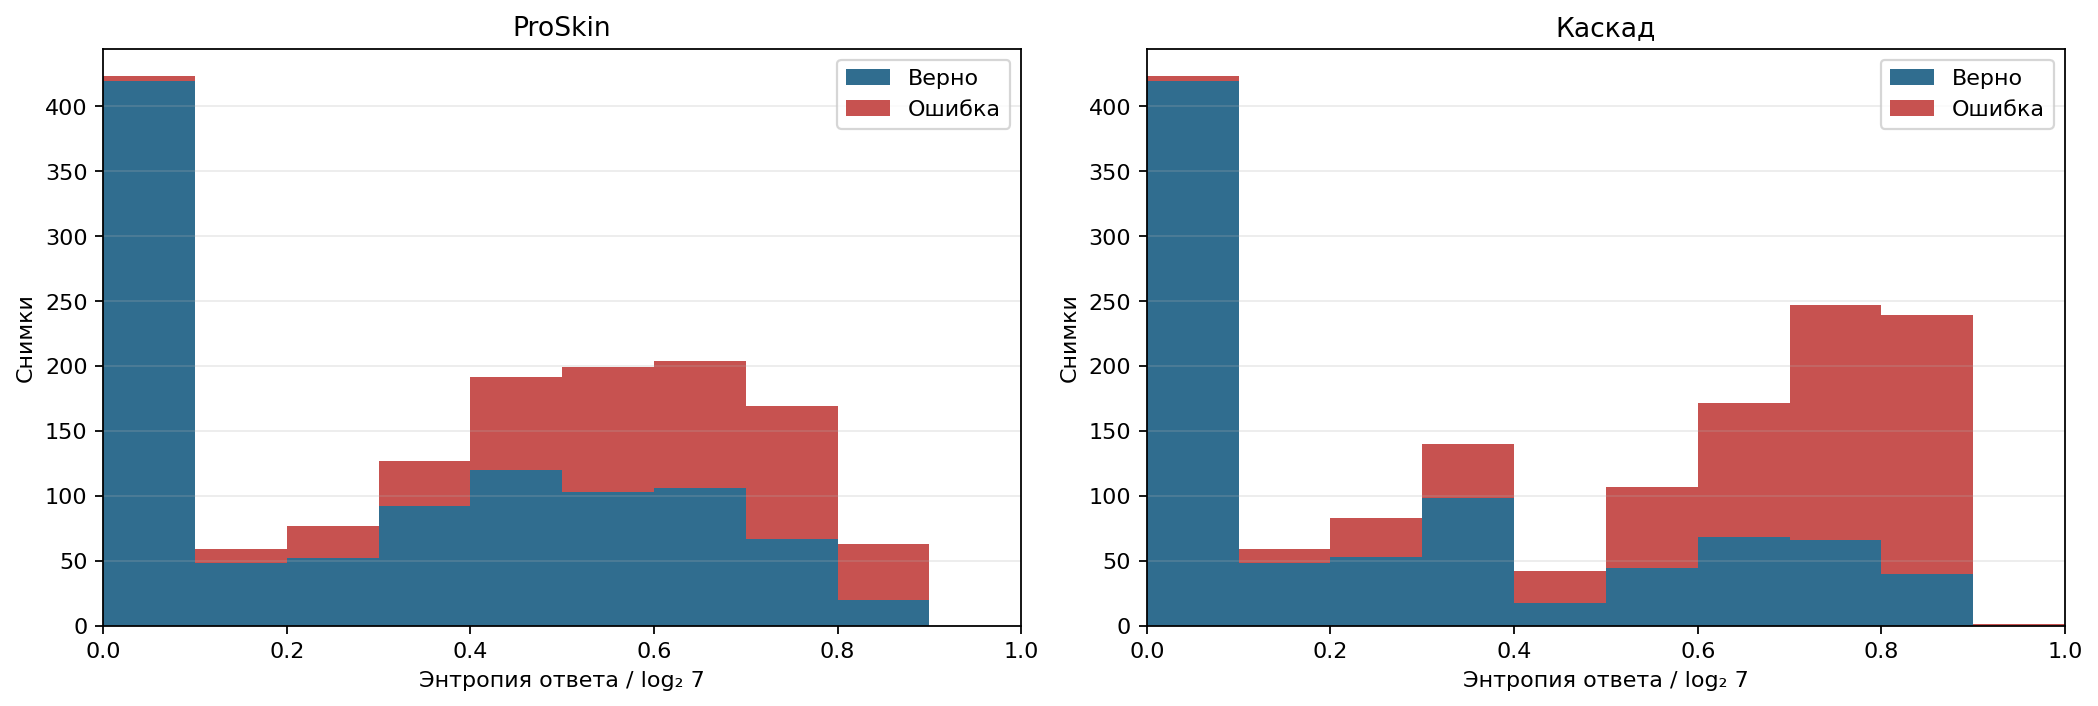

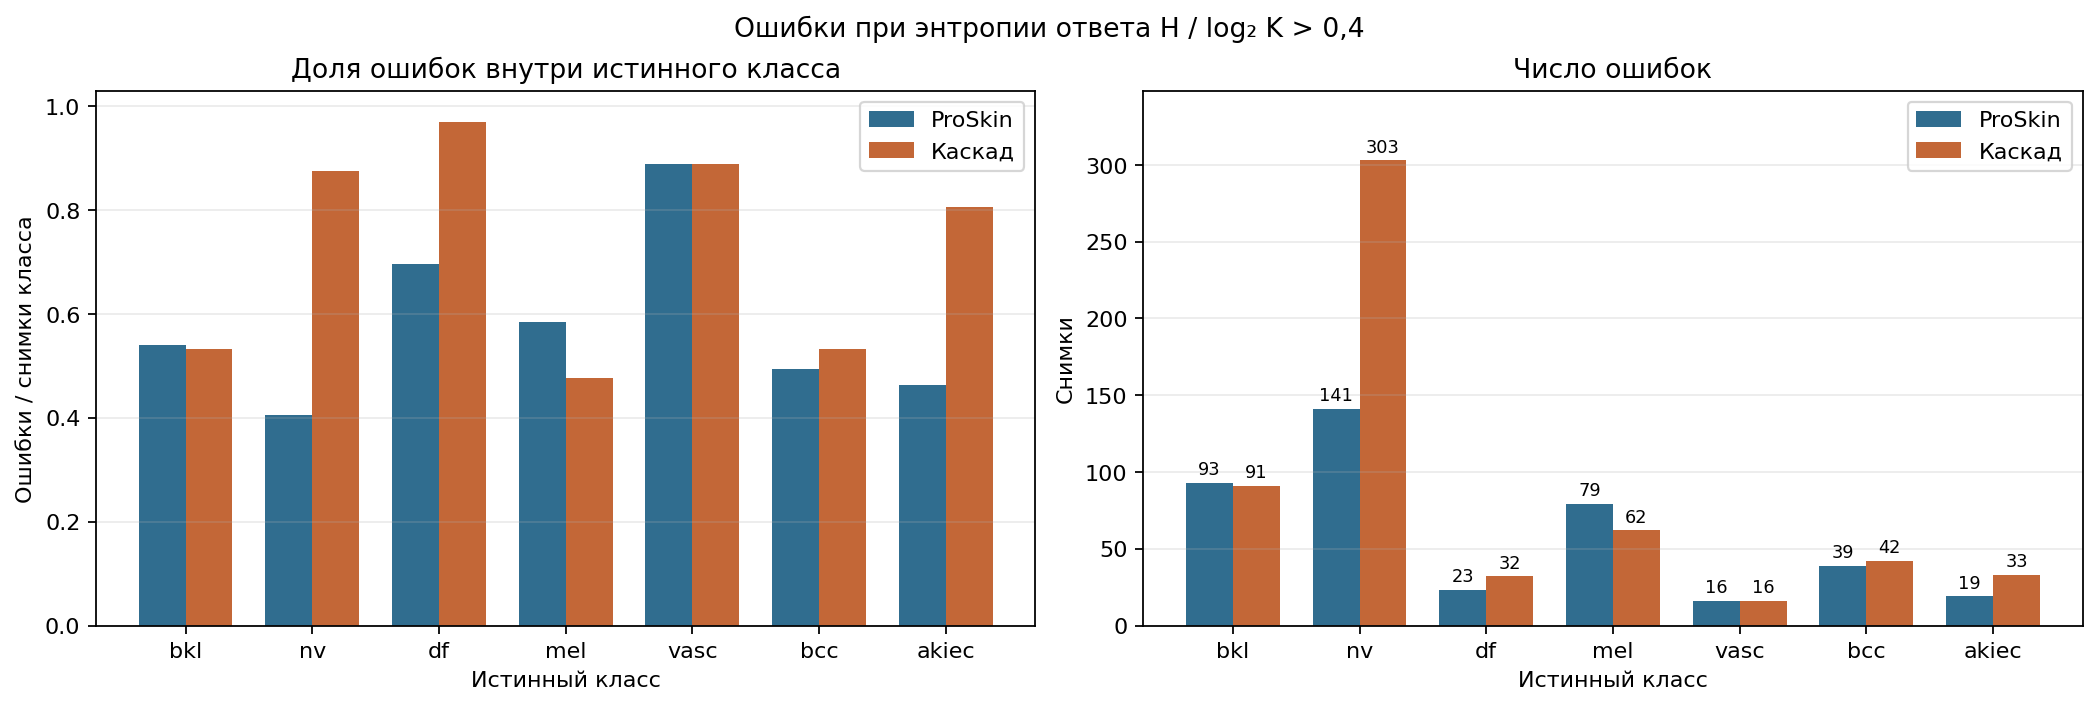

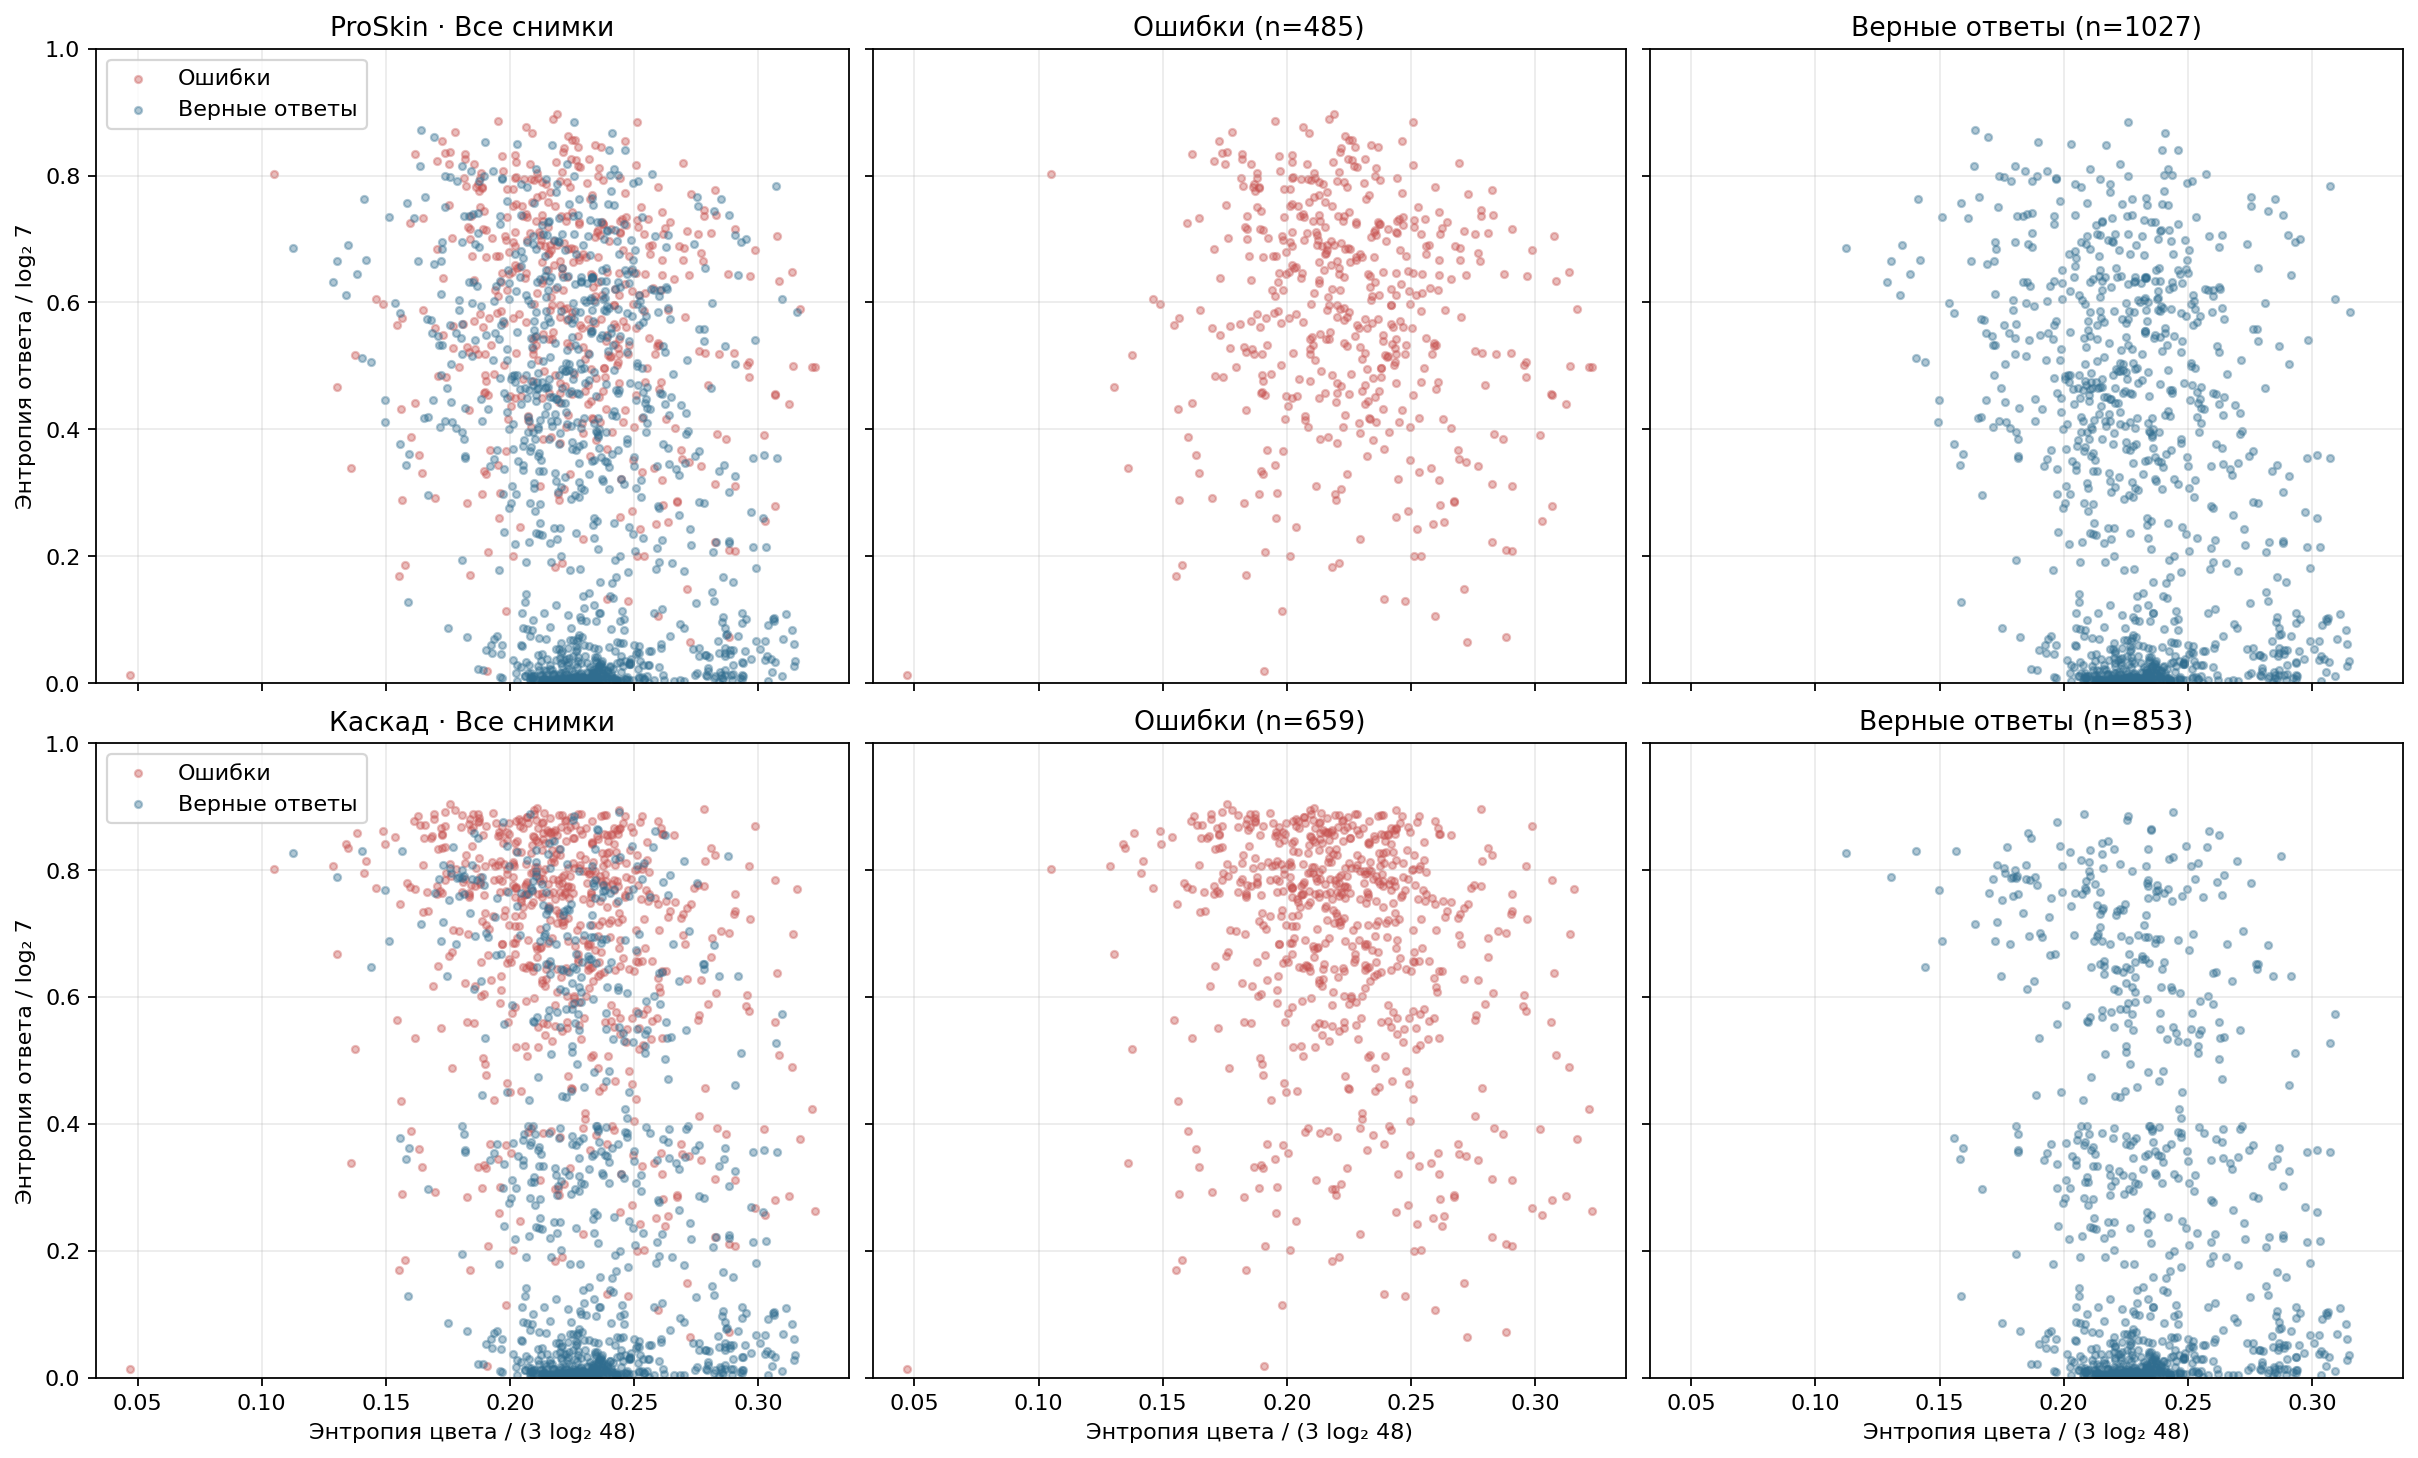

In [ ]:
from IPython.display import Image, display

display(Image(filename='graphics/proskin-cascade-0.4/output_entropy.png'))
display(Image(filename='graphics/proskin-cascade-0.4/high_entropy_class_errors.png'))
display(Image(filename='graphics/proskin-cascade-0.4/image_and_output_entropy.png'))


### Воспроизведение

Команда из папки проекта — `python evaluate_proskin_cascade.py --threshold 0.4`. Все файлы этого запуска лежат в `graphics/proskin-cascade-0.4/`. Сохранили [ответы и энтропии по снимкам](graphics/proskin-cascade-0.4/predictions.csv), [метрики по классам](graphics/proskin-cascade-0.4/per_class_metrics.csv), [диапазоны энтропии](graphics/proskin-cascade-0.4/entropy_error_rates.csv) и [итоговые метрики](graphics/proskin-cascade-0.4/metrics.json).

## Как порог энтропии влияет на качество каскада ProSkin

Проверили 101 порог от 0,00 до 1,00 с шагом 0,01 на тех же 1512 снимках ISIC 2018. Для каждого снимка один раз получили ответ базовой ProSkin и, если базовый ответ допускает передачу, ответ соответствующего специалиста. Для каждого порога заново выбрали итоговые классы. Если энтропия базовой ProSkin достигла порога, используем класс специалиста. Ответ `vasc` сохраняется при любом пороге.

| Порог | Снимков передано | Macro F1 | Weighted F1 | Точность, % | Ошибок |
|---|---:|---:|---:|---:|---:|
| Базовая ProSkin | 0 | 0,4870 | 0,6871 | 67,92 | 485 |
| 0,00 | 1471 | 0,3349 | 0,5582 | 52,38 | 720 |
| 0,30 | 933 | 0,3645 | 0,5769 | 54,30 | 691 |
| 0,40 | 811 | 0,3756 | 0,5955 | 56,42 | 659 |
| 0,82 | 38 | 0,4876 | 0,6858 | 67,79 | 487 |
| 0,87 | 6 | 0,4872 | 0,6872 | 67,92 | 485 |
| 1,00 | 0 | 0,4870 | 0,6871 | 67,92 | 485 |

Максимальный macro F1 — **0,4876** при пороге **0,82**. Это на **0,064 п. п.** выше базовой ProSkin. При этом специалисты обработали 38 снимков, а общее число ошибок выросло с 485 до 487. Максимальный weighted F1 — **0,68716** при порогах **0,87–0,88**. Ни один порог не снизил число ошибок ниже 485. Начиная с **0,90**, все ответы даёт базовая ProSkin. Максимумы описывают эту тестовую выборку.

[Таблица метрик для всех 101 порога](graphics/proskin-cascade-threshold-sweep/threshold_metrics.csv). Команда для воспроизведения — `python sweep_proskin_thresholds.py`.


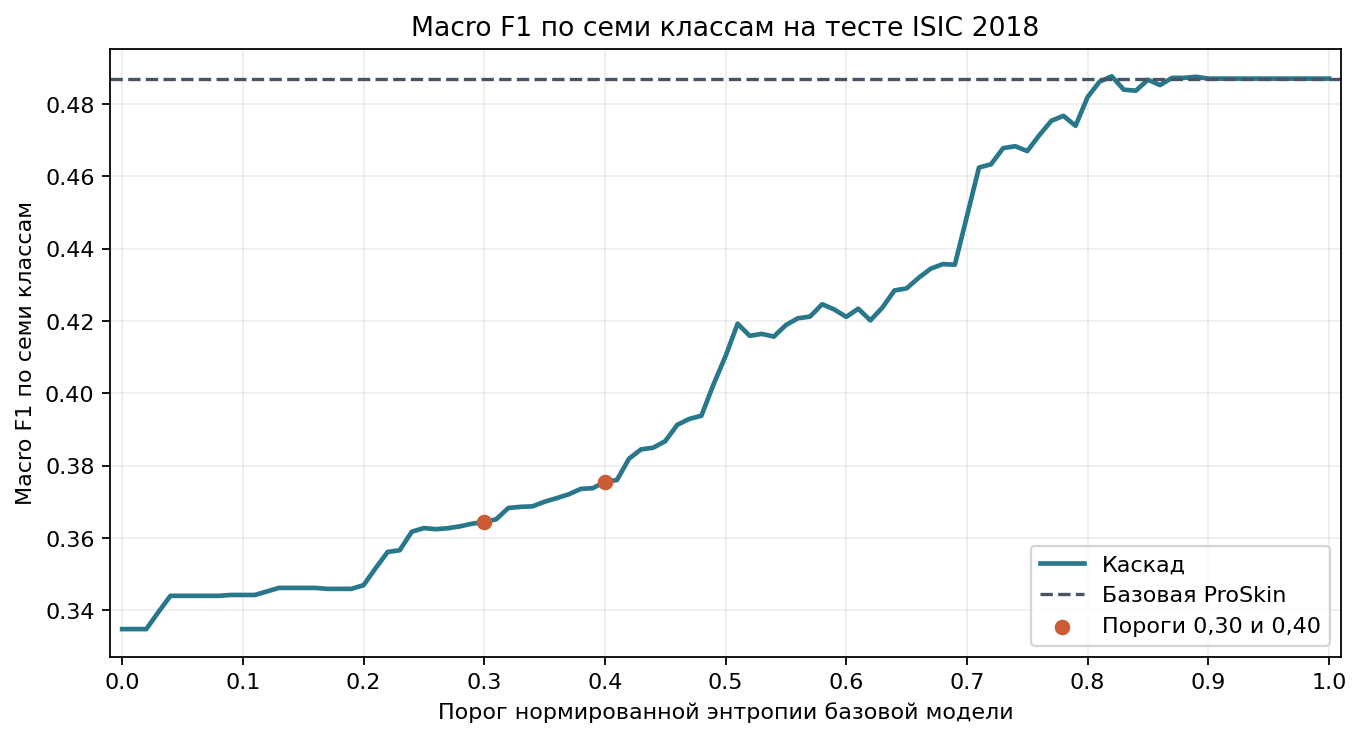

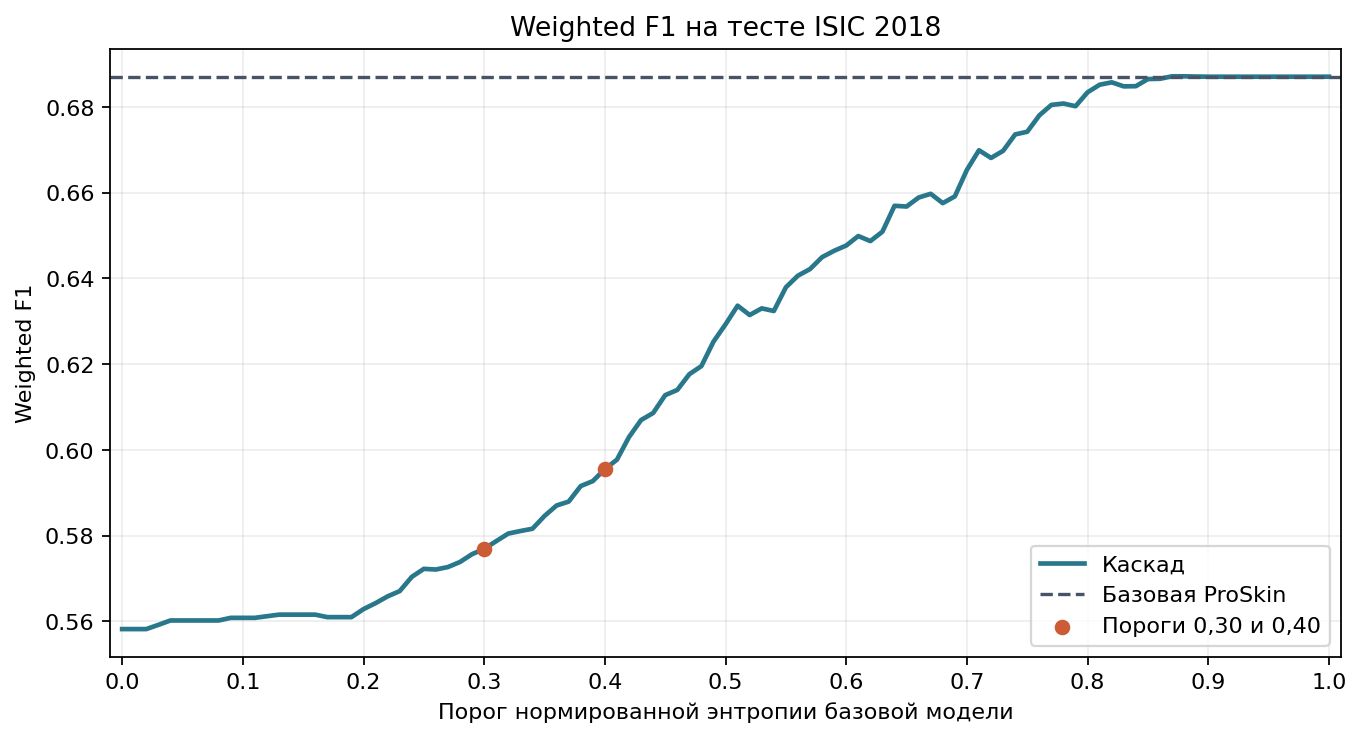

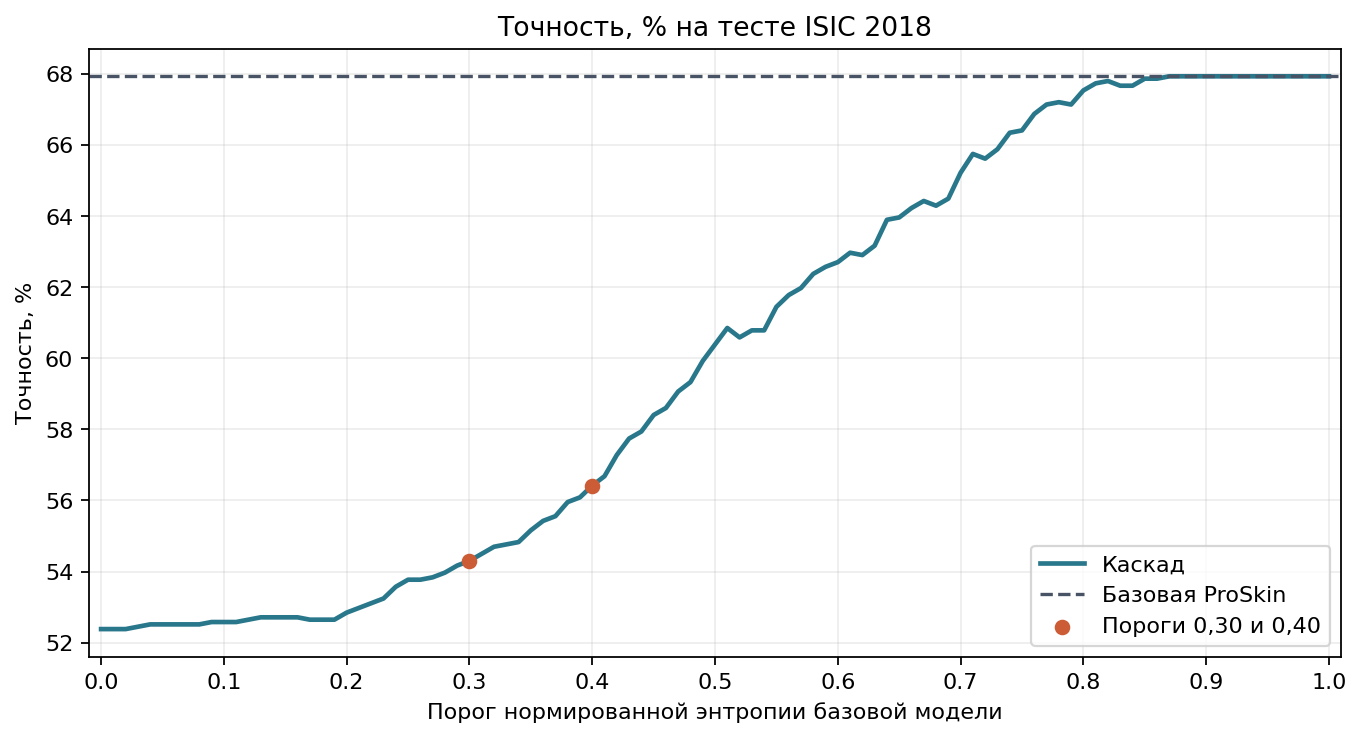

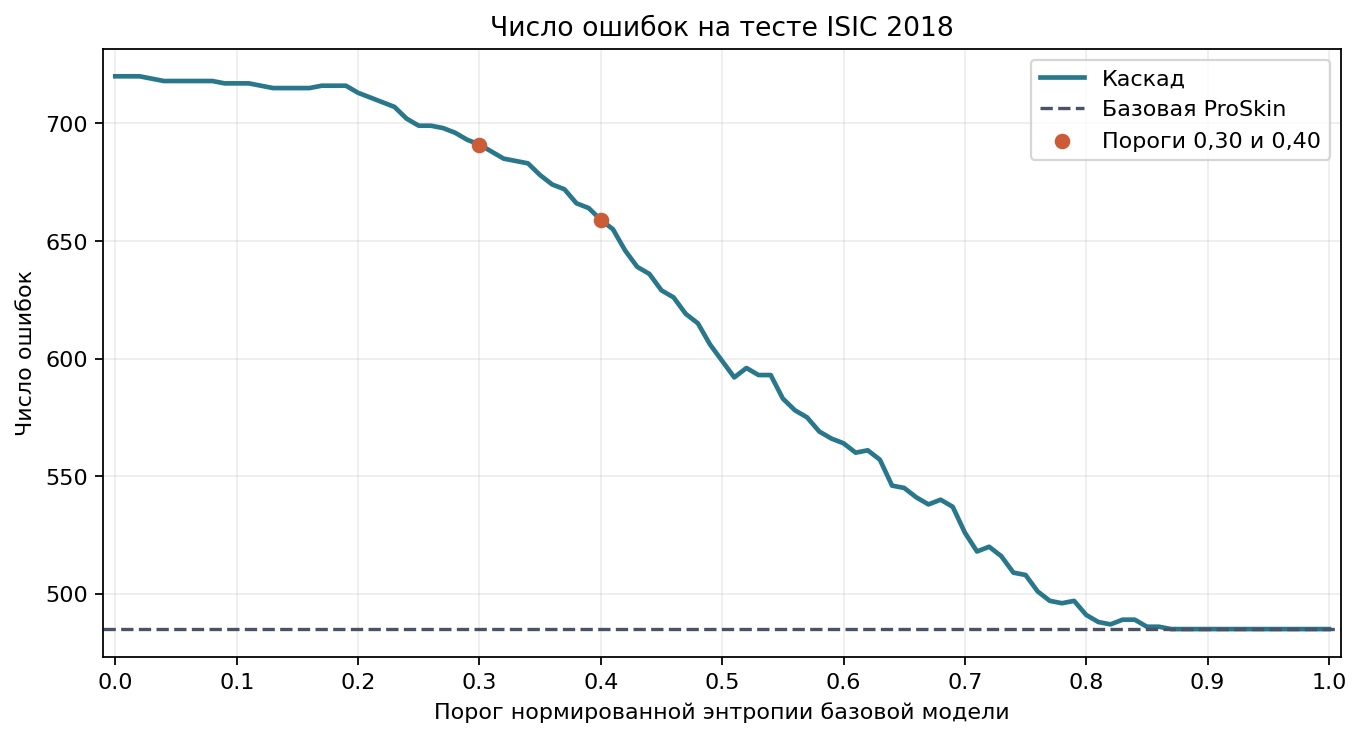

In [ ]:
from IPython.display import Image, display

display(Image(filename='graphics/proskin-cascade-threshold-sweep/macro_f1_vs_threshold.png'))
display(Image(filename='graphics/proskin-cascade-threshold-sweep/weighted_f1_vs_threshold.png'))
display(Image(filename='graphics/proskin-cascade-threshold-sweep/accuracy_vs_threshold.png'))
display(Image(filename='graphics/proskin-cascade-threshold-sweep/errors_vs_threshold.png'))